# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1**, Tecnicatura en Inteligencia Artificial
Facultad de Ciencias Exactas, Ingeniería y Agrimensura (UNR). 2026, cuatrimestre 2

**Integrantes:** Sofia Grando, Amanda Tardugno, Lucas Díaz y Facundo Ferreira

Predecimos `RainTomorrow`: si al día siguiente llueve o no en una ciudad de Australia, a partir
de lo que se midió ese día. La respuesta es una de dos categorías, así que es un problema de
clasificación binaria. El modelo tiene que poder usarse a las 23:59 de cada día, y eso define qué
información puede usar: sólo la que a esa hora ya se conoce.

## Configuración del entorno

In [1]:
# Las bibliotecas que usamos en todo el notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Estilo de los gráficos, opciones de salida y semilla fija, para que todo salga igual cada vez que corremos
import warnings

warnings.filterwarnings("ignore", message=r"\[IterativeImputer\] Early stopping criterion not reached")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Análisis descriptivo y preprocesamiento

## Carga e inspección estructural

In [3]:
# El csv está en la misma carpeta que el notebook
df = pd.read_csv("weatherAUS_2026C2.csv")
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,19.0,25.0,68.8,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,23.0,40.1,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,20.0,27.0,36.2,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,10.0,10.0,45.8,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,6.0,17.0,83.5,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


In [4]:
# Dimensiones y tipo de dato de cada variable
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.dtypes.to_frame("tipo")

Filas: 145412  |  Columnas: 25


,tipo
Unnamed: 0,int64
Date,str
Location,str
MinTemp,float64
MaxTemp,float64
Rainfall,float64
Evaporation,float64
Sunshine,float64
WindGustDir,str
WindGustSpeed,float64


In [5]:
# Filas repetidas, y ciudades con más de un registro para el mismo día
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")
print(f"Pares fecha-ciudad repetidos: {df.duplicated(['Date', 'Location']).sum()}")

Filas duplicadas exactas: 0
Pares fecha-ciudad repetidos: 0


### Las variables

Las definiciones son las de la
[descripción del dataset en Kaggle](https://www.kaggle.com/datasets/arunavakrchakraborty/australia-weather-data/data),
que a su vez las toma del servicio meteorológico de Australia, de donde salen las observaciones.

| Variable | Qué mide | Tipo |
|---|---|---|
| `Date` | Fecha de la observación | fecha |
| `Location` | Ciudad de Australia donde está la estación | categórica nominal |
| `MinTemp` | Temperatura mínima del día, en °C | numérica continua |
| `MaxTemp` | Temperatura máxima del día, en °C | numérica continua |
| `Rainfall` | Lluvia del día, en mm | numérica continua |
| `Evaporation` | Evaporación del día, en mm | numérica continua |
| `Sunshine` | Horas de sol pleno en el día | numérica continua |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día, en 16 rumbos | categórica cíclica |
| `WindGustSpeed` | Velocidad de esa ráfaga, en km/h | numérica continua |
| `WindDir9am`, `WindDir3pm` | Dirección del viento en los 10 minutos previos a las 9 y a las 15, en 16 rumbos | categórica cíclica |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento en los 10 minutos previos a las 9 y a las 15, en km/h | numérica continua |
| `Humidity9am`, `Humidity3pm` | Humedad a las 9 y a las 15, en % | numérica continua |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica a las 9 y a las 15, en hPa | numérica continua |
| `Cloud9am`, `Cloud3pm` | Parte del cielo cubierta por nubes a las 9 y a las 15, en octavos (0 despejado, 8 cubierto) | numérica discreta |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 y a las 15, en °C | numérica continua |
| `RainToday` | `Yes` si ese día llovió | binaria |
| **`RainTomorrow`** | **`Yes` si al día siguiente llueve: variable a predecir** | **binaria** |
| `RainfallTomorrow` | No figura en la descripción; por el nombre, la lluvia del día siguiente, en mm | numérica continua |
| `Unnamed: 0` | No figura en la descripción | entera |

Los tipos que asignó pandas son los que corresponden, con una excepción: `Date` entró como texto y
hay que pasarla a fecha. Las tres direcciones de viento son categóricas, pero no nominales
comunes: los 16 rumbos dan la vuelta, y `N` está tan cerca de `NNW` como de `NNE`. Eso pesa en cómo
codificarlas.

Hay dos columnas que no son observaciones del día. `Unnamed: 0` no tiene nombre y parece un número
de fila. `RainfallTomorrow` es la lluvia del día siguiente, que a las 23:59 del día actual todavía no
se conoce, y si `RainTomorrow` se arma a partir de ella sería la respuesta escrita de otra forma.

In [6]:
# Si Unnamed: 0 es un número de fila, tiene que ser único y creciente
print(f"Valores únicos: {df['Unnamed: 0'].is_unique}  |  Creciente: {df['Unnamed: 0'].is_monotonic_increasing}")

Valores únicos: True  |  Creciente: True


In [7]:
# RainTomorrow contra RainfallTomorrow cortada en 1 mm
con_valor = df["RainTomorrow"].notna()
coincide = (df.loc[con_valor, "RainfallTomorrow"] > 1) == (df.loc[con_valor, "RainTomorrow"] == "Yes")
print(f"Filas donde RainTomorrow coincide con RainfallTomorrow > 1 mm: {coincide.mean():.2%}")

Filas donde RainTomorrow coincide con RainfallTomorrow > 1 mm: 100.00%


In [8]:
# Lo mismo para el día actual: RainToday contra Rainfall
con_valor = df["RainToday"].notna()
coincide = (df.loc[con_valor, "Rainfall"] > 1) == (df.loc[con_valor, "RainToday"] == "Yes")
print(f"Filas donde RainToday coincide con Rainfall > 1 mm: {coincide.mean():.2%}")

Filas donde RainToday coincide con Rainfall > 1 mm: 100.00%


In [9]:
# RainfallTomorrow de un día contra Rainfall del día siguiente en la misma ciudad
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Location", "Date"]).reset_index(drop=True)
siguiente = df.groupby("Location")[["Date", "Rainfall"]].shift(-1)
comparables = (siguiente["Date"] - df["Date"]).dt.days.eq(1) & df["RainfallTomorrow"].notna() & siguiente["Rainfall"].notna()
iguales = np.isclose(df.loc[comparables, "RainfallTomorrow"], siguiente.loc[comparables, "Rainfall"])
print(f"Días consecutivos comparados: {comparables.sum()}  |  RainfallTomorrow igual al Rainfall del día siguiente: {iguales.mean():.2%}")

Días consecutivos comparados: 141970  |  RainfallTomorrow igual al Rainfall del día siguiente: 100.00%


Las tres comparaciones dan 100%. `RainTomorrow` es `RainfallTomorrow` cortada en 1 mm, y
`RainfallTomorrow` es el `Rainfall` que la misma estación anota al día siguiente. Con esa columna
el modelo acertaría siempre mirando una sola variable, y en producción esa variable no existe,
porque es justo lo que queremos averiguar. La sacamos, junto con `Unnamed: 0`, que es único y
creciente: un número de fila que no describe el clima.

`RainToday` tiene la misma relación con `Rainfall`: es `Rainfall` cortada en 1 mm. Ahí no hay fuga,
porque las dos se conocen el mismo día, pero sí significa que `RainToday` no tiene ninguna
información que no esté ya en `Rainfall`.

In [10]:
# Sacamos el número de fila y la columna con la respuesta
df = df.drop(columns=["Unnamed: 0", "RainfallTomorrow"])
print(f"Columnas que quedan: {df.shape[1]}")

Columnas que quedan: 23


## Análisis descriptivo

In [11]:
# Medidas de tendencia central y dispersión de las variables numéricas
df.describe(include="number").T.round(2)

,count,mean,std,min,25%,50%,75%,max
MinTemp,143928.0,12.20,6.42,-9.7,7.6,12.0,16.9,34.1
MaxTemp,144159.0,23.22,7.14,-5.1,17.9,22.6,28.2,49.1
Rainfall,142152.0,2.36,8.48,0.0,0.0,0.0,0.8,371.0
Evaporation,82658.0,5.47,4.19,0.0,2.6,4.8,7.4,145.0
Sunshine,75616.0,7.61,3.79,0.0,4.8,8.4,10.6,14.5
WindGustSpeed,135159.0,40.04,13.65,6.0,31.0,38.0,48.0,135.0
WindSpeed9am,143645.0,14.07,8.94,0.0,7.0,13.0,19.0,130.0
WindSpeed3pm,142351.0,18.66,8.87,0.0,12.0,18.0,24.0,86.0
Humidity9am,142759.0,68.86,19.06,0.0,57.0,69.9,83.1,100.0
Humidity3pm,140907.0,51.53,20.84,0.0,36.6,52.0,65.7,100.0


In [12]:
# El sesgo mide la asimetría: lejos de 0 quiere decir que hay una cola larga
df.skew(numeric_only=True).sort_values(ascending=False).to_frame("sesgo").round(2)

,sesgo
Rainfall,9.83
Evaporation,3.76
WindGustSpeed,0.87
WindSpeed9am,0.79
WindSpeed3pm,0.62
Temp3pm,0.24
MaxTemp,0.22
Temp9am,0.09
Humidity3pm,0.03
MinTemp,0.02


In [13]:
# Valores distintos y valor más frecuente de cada variable categórica
df.describe(exclude=["number", "datetime"]).T

,count,unique,top,freq
Location,145412,49,Canberra,3435
WindGustDir,135096,16,W,9910
WindDir9am,134850,16,N,11754
WindDir3pm,141186,16,SE,10837
RainToday,142152,2,No,110276
RainTomorrow,142153,2,No,110281


In [14]:
# Período que cubre cada ciudad y cuántos días tiene registrados
cobertura = df.groupby("Location")["Date"].agg(desde="min", hasta="max", dias="count")
cobertura["dias sin registro"] = (cobertura["hasta"] - cobertura["desde"]).dt.days + 1 - cobertura["dias"]
cobertura.sort_values(["desde", "dias"])

,desde,hasta,dias,dias sin registro
Location,,,,
Canberra,2007-11-01,2017-06-24,3435,89
Sydney,2008-02-01,2017-06-24,3343,89
Adelaide,2008-07-01,2017-06-24,3192,89
Brisbane,2008-07-01,2017-06-24,3192,89
Darwin,2008-07-01,2017-06-24,3192,89
Hobart,2008-07-01,2017-06-24,3192,89
Melbourne,2008-07-01,2017-06-24,3192,89
Perth,2008-07-01,2017-06-24,3192,89
Penrith,2008-12-01,2017-06-24,3038,90


In [15]:
# Días del período en los que no hay registro de ninguna ciudad, agrupados por mes
todas_las_fechas = pd.date_range(df["Date"].min(), df["Date"].max())
sin_registro = todas_las_fechas.difference(df["Date"].unique())
print(f"Días sin ningún registro: {len(sin_registro)}")
pd.Series(sin_registro).dt.to_period("M").value_counts().sort_index().to_frame("días")

Días sin ningún registro: 89


,días
2011-04,30
2012-12,31
2013-02,28


In [16]:
# Si las cuatro temperaturas son del mismo día, las de las 9 y las 15 caen entre la mínima y la máxima: contamos cuándo no
comparaciones = {"MinTemp > MaxTemp": df["MinTemp"] - df["MaxTemp"],
                 "Temp9am < MinTemp": df["MinTemp"] - df["Temp9am"], "Temp9am > MaxTemp": df["Temp9am"] - df["MaxTemp"],
                 "Temp3pm > MaxTemp": df["Temp3pm"] - df["MaxTemp"], "Temp3pm < MinTemp": df["MinTemp"] - df["Temp3pm"]}
pd.DataFrame({nombre: {"filas": (dif > 0).sum(), "diferencia mediana (°C)": dif[dif > 0].median(),
                       "diferencia máxima (°C)": dif.max(), "filas con más de 2 °C": (dif > 2).sum()}
              for nombre, dif in comparaciones.items()}).T.round(1)

,filas,diferencia mediana (°C),diferencia máxima (°C),filas con más de 2 °C
MinTemp > MaxTemp,70.0,0.3,1.3,0.0
Temp9am < MinTemp,2044.0,0.4,2.4,3.0
Temp9am > MaxTemp,627.0,0.4,2.7,1.0
Temp3pm > MaxTemp,11944.0,0.4,2.5,9.0
Temp3pm < MinTemp,1490.0,0.9,10.6,290.0


In [17]:
# Nubosidad en 9, fuera de la escala de 0 a 8 octavos
print(f"Cloud9am = 9: {(df['Cloud9am'] == 9).sum()}  |  Cloud3pm = 9: {(df['Cloud3pm'] == 9).sum()}")

Cloud9am = 9: 2  |  Cloud3pm = 9: 1


### Cada variable, una por una

#### Las temperaturas

- `MinTemp` (−9,7 a 34,1 °C, mediana 12,0) y `MaxTemp` (−5,1 a 49,1 °C, mediana 22,6) son casi
  simétricas (sesgo 0,02 y 0,22). El rango es enorme porque mezcla 49 ciudades en todas las
  estaciones del año.
- `Temp9am` (−8,0 a 39,8 °C, mediana 16,7) y `Temp3pm` (−5,8 a 47,0 °C, mediana 21,1) se comportan
  igual, también simétricas. Por cómo están definidas, `Temp9am` debería parecerse a la mínima y
  `Temp3pm` a la máxima.
- Las cuatro no siempre son coherentes entre sí. Hay 70 filas con la mínima por encima de la
  máxima, y miles con la temperatura de las 9 o de las 15 fuera del rango entre las dos. Pero cuatro
  de esas cinco inconsistencias son chicas: nunca pasan de 2,7 °C y la mitad no llega a medio grado
  (en las 70 filas de mínima mayor que máxima, la diferencia es de 0,3 °C en la mediana y 1,3 °C como
  mucho). Al aparecer en miles de filas no son unas pocas filas corruptas sino un margen de
  imprecisión de alrededor de un grado en todo el archivo.
- La quinta es distinta: `Temp3pm` queda por debajo de la mínima en 1.490 filas, 290 de ellas por
  más de 2 °C y hasta 10,6 °C. Eso no se explica con imprecisión. Sí se explica si la mínima no es la
  del día calendario sino la de un período que termina a la mañana: entonces un día que se enfría
  durante la tarde puede tener a las 15 menos temperatura que a la madrugada. Es la única de las cinco
  comparaciones que fallaría en ese caso, y es la única con diferencias grandes. La descripción del
  dataset no aclara el horario de la mínima, así que lo tomamos como la explicación más compatible
  con los datos, no como un hecho.
- No corregimos nada. Para corregir habría que saber cuál de las temperaturas de cada fila es la
  equivocada, y no hay forma de saberlo; sacar las filas implicaría descartar más de 15.000 por
  diferencias de medio grado.

#### La lluvia y la evaporación

- `Rainfall` (0 a 371 mm, mediana 0) es la más asimétrica del conjunto (sesgo 9,83). Más de la mitad
  de los días no llueve nada y tres de cada cuatro llueve menos de 0,8 mm, pero hay días con
  cientos de milímetros.
- `Evaporation` (0 a 145 mm, mediana 4,8) tiene la misma forma con una cola menos larga (sesgo
  3,76): el 75% de los días evapora menos de 7,4 mm.
- `RainToday` es `No` en 110.276 días y `Yes` en 31.876, más de tres a uno.

#### El sol y las nubes

- `Sunshine` (0 a 14,5 h, mediana 8,4) es la única con sesgo negativo apreciable (−0,50): la
  mayoría de los días tiene muchas horas de sol.
- `Cloud9am` y `Cloud3pm` (mediana 5) toman valores enteros de 0 a 8. Hay 3 valores en 9, fuera de
  la escala; son tan pocos que no cambian nada y los dejamos.

#### El viento

- `WindGustSpeed` (6 a 135 km/h, mediana 38), `WindSpeed9am` (0 a 130 km/h, mediana 13) y
  `WindSpeed3pm` (0 a 86 km/h, mediana 18) tienen sesgo positivo moderado (0,6 a 0,9): mayoría de
  días de viento moderado y una cola de días de viento fuerte.
- Las tres direcciones toman los 16 rumbos. Los más frecuentes son `W` para la ráfaga, `N` a la
  mañana y `SE` a la tarde.

#### La humedad y la presión

- `Humidity9am` (mediana 69,9) y `Humidity3pm` (mediana 52,0) van de 0 a 100%. La humedad baja
  de la mañana a la tarde, a medida que el aire se calienta.
- `Pressure9am` (980,3 a 1041,2 hPa, mediana 1017,6) y `Pressure3pm` (977,4 a 1039,8 hPa, mediana
  1015,2) son simétricas y con un rango chico en términos relativos: ±3% alrededor de 1015.

#### La fecha y la ciudad

- Hay 49 ciudades, con datos desde el 1/11/2007 hasta el 24/6/2017. Casi todas tienen alrededor de
  3.000 días; las excepciones son Nhil, Uluru y Katherine, que arrancan en marzo de 2013 y tienen la
  mitad.
- A todas las ciudades les faltan los mismos 89 días, que son tres meses enteros: abril de 2011,
  diciembre de 2012 y febrero de 2013. No es que una estación dejó de medir: esos meses no están en
  el archivo.

### Lectura del descriptivo

Las escalas no tienen nada que ver entre sí: la presión anda por 1.015, la humedad entre 0 y 100,
la nubosidad entre 0 y 8. La regresión logística ajusta sus coeficientes por un método iterativo
que converge mal con escalas dispares, y si se la regulariza la penalización mira el tamaño de los
coeficientes, que depende de la unidad de cada variable. Hay que escalar.

`Rainfall` y `Evaporation` tienen colas largas, con valores extremos que no son errores (un día de
371 mm es una tormenta, no un dato mal cargado). Qué hacer con ellos lo decidimos mirando la
relación con la variable a predecir.

## Análisis y decisión sobre datos faltantes

In [18]:
# Cantidad y porcentaje de valores faltantes en cada variable
faltantes = df.isna().sum()
pd.DataFrame({"faltantes": faltantes, "% del total": (faltantes / len(df) * 100).round(2)}).sort_values("faltantes", ascending=False)

,faltantes,% del total
Sunshine,69796,48.00
Evaporation,62754,43.16
Cloud3pm,59336,40.81
Cloud9am,55870,38.42
Pressure9am,15061,10.36
Pressure3pm,15024,10.33
WindDir9am,10562,7.26
WindGustDir,10316,7.09
WindGustSpeed,10253,7.05
Humidity3pm,4505,3.10


Hay faltantes en todo menos la fecha y la ciudad, en proporciones muy distintas. Cuatro variables
pasan el 38% (`Sunshine` 48%, `Evaporation` 43%, `Cloud3pm` 41%, `Cloud9am` 38%), las dos presiones
rondan el 10% y el resto queda por debajo del 7,5%. Ninguna decisión única sirve para todas: un 2%
se puede eliminar casi sin perder nada, mientras que un 48% es media columna.

### Las filas sin la variable a predecir

`RainTomorrow` falta en 3.259 filas, el 2,24%. Esas filas no sirven: para entrenar no tienen
respuesta, y en prueba no habría contra qué comparar. Imputarla sería entrenar contra algo que
inventamos nosotros. Las eliminamos.

In [19]:
# Eliminamos las filas sin RainTomorrow
filas_originales = len(df)
df = df.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
print(f"Filas antes: {filas_originales}  |  Filas después: {len(df)}  |  Eliminadas: {filas_originales - len(df)}")

Filas antes: 145412  |  Filas después: 142153  |  Eliminadas: 3259


### Dónde faltan

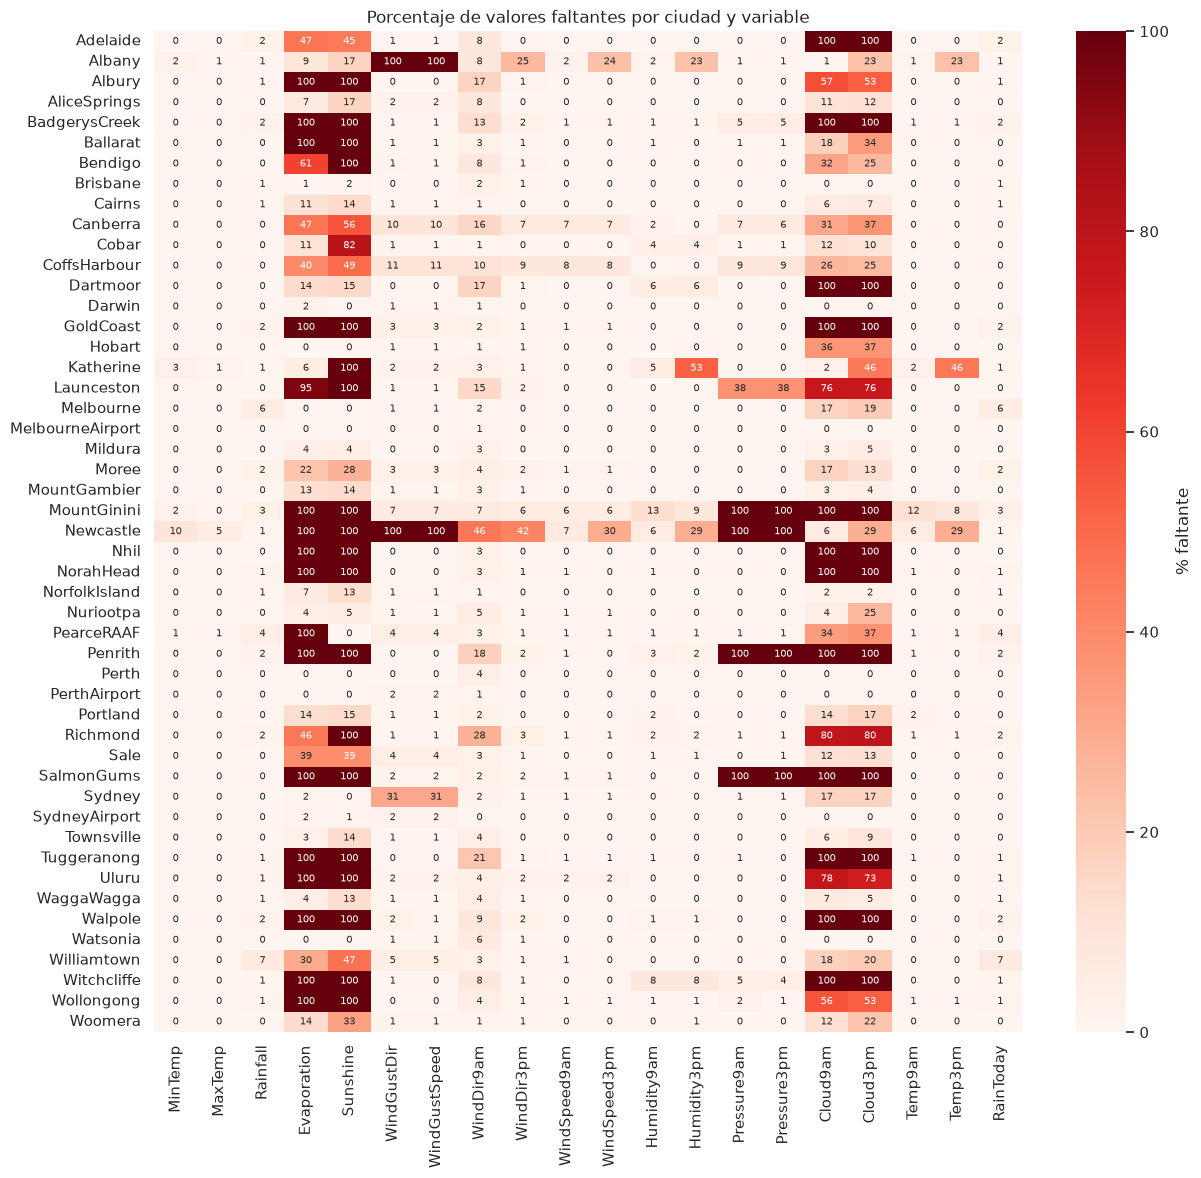

In [20]:
# Porcentaje de faltantes de cada variable en cada ciudad
VARIABLES = df.columns.drop(["Date", "Location", "RainTomorrow"])
faltantes_ciudad = df[VARIABLES].isna().groupby(df["Location"]).mean().mul(100)
plt.figure(figsize=(14, 13))
sns.heatmap(faltantes_ciudad, cmap="Reds", annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "% faltante"})
plt.title("Porcentaje de valores faltantes por ciudad y variable")
plt.xlabel("")
plt.ylabel("")
plt.show()

*Figura 1. Porcentaje de valores faltantes de cada variable en cada ciudad, sobre las filas con `RainTomorrow`.*

In [21]:
# Para cada variable: en cuántas ciudades no hay ni un dato, y qué parte de sus faltantes explican esas ciudades
nunca = faltantes_ciudad.ge(99)
falta = df[VARIABLES].isna()
pd.DataFrame({
    "ciudades sin ningún dato": nunca.sum(),
    "faltantes totales": falta.sum(),
    "% explicado por esas ciudades": [falta.loc[df["Location"].isin(nunca.index[nunca[c]]), c].sum() / falta[c].sum() * 100
                                      for c in VARIABLES],
}).sort_values("faltantes totales", ascending=False).round(1)

,ciudades sin ningún dato,faltantes totales,% explicado por esas ciudades
Sunshine,19,67785,76.8
Evaporation,16,60812,72.8
Cloud3pm,12,57076,59.6
Cloud9am,12,53641,63.4
Pressure9am,4,14010,84.1
Pressure3pm,4,13977,84.3
WindDir9am,0,10009,0.0
WindGustDir,2,9328,64.0
WindGustSpeed,2,9268,64.4
WindDir3pm,0,3776,0.0


Los faltantes no están repartidos al azar (Figura 1): hay columnas en 100 para algunas ciudades y en
0 para otras. Hay estaciones que directamente no miden algunas cosas. 19 ciudades no tienen ni un
valor de `Sunshine`, 16 no tienen `Evaporation`, 12 no tienen nubosidad, 4 no tienen presión y 2 no
registran ráfagas. Esas ciudades explican entre el 60% y el 84% de los faltantes de cada una de esas
variables. El resto de los faltantes, y todos los de las demás variables, son huecos sueltos en
estaciones que normalmente sí miden.

In [22]:
# Porcentaje de faltantes por año, para las variables que alguna vez pasan el 5%
faltantes_anio = df[VARIABLES].isna().groupby(df["Date"].dt.year).mean().mul(100)
faltantes_anio.loc[:, faltantes_anio.max() > 5].round(1)

,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp3pm
Date,,,,,,,,,,,
2007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008,14.5,14.2,19.9,19.9,4.0,0.9,4.2,4.1,15.9,16.3,0.6
2009,33.7,36.5,9.5,9.5,7.7,1.2,9.8,9.8,32.6,34.0,1.0
2010,34.1,35.9,7.8,7.8,8.4,1.0,8.9,8.8,31.8,32.7,0.9
2011,37.2,39.0,6.3,6.3,6.6,0.8,10.0,9.9,37.6,39.2,0.7
2012,38.6,41.8,5.3,5.3,7.3,2.5,8.9,8.9,37.4,39.2,0.8
2013,38.8,46.0,5.0,4.8,6.7,1.0,8.4,8.4,40.9,41.2,0.4
2014,45.4,50.8,6.3,6.3,8.1,0.8,11.2,11.2,39.5,39.9,0.3
2015,49.1,53.2,5.4,5.3,6.5,3.9,11.5,11.5,38.3,40.7,2.8


En el tiempo la mayoría se mantiene estable, salvo `Sunshine` y `Evaporation`, que empeoran año a
año: `Sunshine` pasa de 36,5% faltante en 2009 a 73,8% en 2017, y `Evaporation` de 33,7% a 66,6%.
Hay cada vez menos estaciones que las miden. (2007 y 2008 no cuentan: son los meses en que el
archivo tiene sólo unas pocas ciudades.)

In [23]:
# Las direcciones de viento faltantes, separadas según la velocidad del mismo momento
pd.DataFrame({
    direccion: {"direcciones faltantes": df[direccion].isna().sum(),
                "con velocidad 0": (df.loc[df[direccion].isna(), velocidad] == 0).sum(),
                "con velocidad también faltante": df.loc[df[direccion].isna(), velocidad].isna().sum(),
                "filas con velocidad 0 (total)": (df[velocidad] == 0).sum()}
    for direccion, velocidad in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm"), ("WindGustDir", "WindGustSpeed")]
})

,WindDir9am,WindDir3pm,WindGustDir
direcciones faltantes,10009,3776,9328
con velocidad 0,5931,744,0
con velocidad también faltante,1348,2629,9268
filas con velocidad 0 (total),6237,805,0


En `WindDir9am`, 5.931 de las 10.009 direcciones faltantes son de momentos con velocidad 0, y casi
todas las filas con velocidad 0 (5.931 de 6.237) no tienen dirección. Con el aire quieto no hay
dirección que medir: ahí el hueco no es un dato perdido, es la respuesta correcta escrita como
vacío. En `WindDir3pm` pasa lo mismo con 744 de 3.776. Los demás faltantes coinciden casi siempre
con la velocidad también vacía, o sea que el instrumento no registró nada. `WindGustDir` no tiene
casos de calma: sus faltantes van siempre con `WindGustSpeed` faltante.

### Las filas casi vacías

In [24]:
# Cuántas de las 20 variables le faltan a cada fila
por_fila = df[VARIABLES].isna().sum(axis=1)
por_fila.value_counts().sort_index().to_frame("filas").rename_axis("faltantes en la fila").T

faltantes en la fila,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
filas,56412,10764,18023,9607,28531,3639,9934,1801,964,393,290,679,757,106,39,26,27,91,49,16,5


La mayoría de las filas tiene entre 0 y 6 faltantes, que es lo que se explica por las variables que
cada estación no mide. Después hay una cola de filas a las que les falta la mitad o más.

In [25]:
# Las filas con 10 o más faltantes: cuántas son, de qué ciudades y si llueve distinto en ellas
muy_vacias = por_fila >= len(VARIABLES) / 2
llueve = df["RainTomorrow"].eq("Yes")
print(f"Filas con 10 o más faltantes: {muy_vacias.sum()} ({muy_vacias.mean():.2%})")
print(f"Días con lluvia al día siguiente: {llueve[muy_vacias].mean():.1%} en ellas, {llueve[~muy_vacias].mean():.1%} en el resto")

Filas con 10 o más faltantes: 2085 (1.47%)
Días con lluvia al día siguiente: 27.1% en ellas, 22.4% en el resto


En esas filas llueve más que en el resto, y si las sacamos podríamos estar llevándonos un tipo de
día en particular. Pero también puede ser que estén concentradas en ciudades más lluviosas que el
promedio.

In [26]:
# Por ciudad: lluvia en las filas muy vacías contra el resto de la misma ciudad
tasa_resto = llueve[~muy_vacias].groupby(df.loc[~muy_vacias, "Location"]).mean()
print(f"Esperado si cada fila lloviera como el resto de su ciudad: {df.loc[muy_vacias, 'Location'].map(tasa_resto).mean():.1%}")
pd.DataFrame({"filas muy vacías": muy_vacias.groupby(df["Location"]).sum(),
              "% lluvia en ellas": llueve[muy_vacias].groupby(df.loc[muy_vacias, "Location"]).mean() * 100,
              "% lluvia en el resto": tasa_resto * 100}).sort_values("filas muy vacías", ascending=False).head(6).round(1)

Esperado si cada fila lloviera como el resto de su ciudad: 24.6%


,filas muy vacías,% lluvia en ellas,% lluvia en el resto
Location,,,
Newcastle,922,24.4,24.9
MountGinini,345,41.4,26.4
CoffsHarbour,240,23.8,29.9
Canberra,214,20.6,18.3
Albany,78,29.5,29.9
SalmonGums,42,14.3,16.0


Buena parte de la diferencia es de composición: si cada fila lloviera como el resto de su ciudad
esperaríamos 24,6%, a mitad de camino entre el 22,4% general y el 27,1% observado. Lo que sobra viene casi todo de MountGinini, donde las filas casi
vacías llueven 41,4% contra 26,4% del resto. Ahí la estación parece dejar de registrar justo los
días de mal tiempo, y eso es un faltante que depende del valor que falta. En las demás ciudades
la diferencia va para los dos lados y es chica.

Las eliminamos igual. A una fila a la que le falta la mitad de lo que describe el día, cualquier
imputación le inventa más de lo que tiene medido, y el modelo aprendería sobre todo del método de
imputación. Sumadas a las que no tenían `RainTomorrow`, perdemos el 3,7% del archivo: por debajo
del 5%, que es lo máximo que estamos dispuestos a descartar sin que se sesgue el conjunto. El costo
es concreto, y lo dejamos anotado: Newcastle pierde 922 de sus 3.000 días y MountGinini pierde 345,
entre ellos algunos días de lluvia.

In [27]:
# Eliminamos las filas con la mitad o más de las variables vacías
df = df[~muy_vacias].reset_index(drop=True)
print(f"Filas que quedan: {len(df)}  |  Eliminadas en total: {filas_originales - len(df)} ({(filas_originales - len(df)) / filas_originales:.2%} del original)")

Filas que quedan: 140068  |  Eliminadas en total: 5344 (3.68% del original)


### Diagnóstico y decisión

Los faltantes que quedan son de tres tipos, y cada uno pide algo distinto:

- **Estructurales**: estaciones que nunca miden una variable. Dependen de la ciudad, que es una
  variable que sí tenemos, así que son faltantes MAR (dependen de lo observado, no del valor que
  falta). No hay ningún dato de esa ciudad del cual partir, así que la única forma de estimarlos es
  a partir de las otras variables del mismo día.
- **Huecos sueltos**: días aislados en estaciones que miden. Tampoco encontramos evidencia de que
  dependan del valor que falta.
- **Direcciones de viento con calma**: no son faltantes. Se resuelven al codificar la dirección.

Eliminar más filas no es opción: con los estructurales habría que sacar ciudades enteras. Eliminar
las columnas con más faltantes tampoco nos convence sin antes mirar cuánto informan. Así que hay
que imputar, y la imputación aprende de los datos (una mediana, una regresión), por lo que el método
lo elegimos y lo ajustamos después de dividir, sólo con entrenamiento.

## ¿Está balanceado el dataset?

In [28]:
# Cuántos días llueve al día siguiente y cuántos no
pd.DataFrame({"días": df["RainTomorrow"].value_counts(),
              "%": (df["RainTomorrow"].value_counts(normalize=True) * 100).round(1)})

,días,%
RainTomorrow,,
No,108760,77.6
Yes,31308,22.4


In [29]:
# Accuracy de un clasificador que contesta siempre que no llueve
print(f"Accuracy de predecir siempre 'No': {df['RainTomorrow'].eq('No').mean():.1%}")

Accuracy de predecir siempre 'No': 77.6%


No está balanceado: el 77,6% de los días no llueve al día siguiente y el 22,4% sí, más de tres a
uno. La pregunta importa por lo que le hace al entrenamiento y a la evaluación:

- Un clasificador que contesta siempre "No" acierta el 77,6% de las veces sin aprender nada y sin
  detectar nunca un día de lluvia. La accuracy de un modelo no se compara contra 50% sino contra ese
  77,6%, y aun superándolo puede ser inútil para lo que interesa.
- La regresión logística minimiza un costo que suma el error de todas las filas, y tres de cada
  cuatro son "No". Puede bajar el costo total sacrificando la clase chica, que es justamente la que
  queremos detectar.

No es un desbalance extremo, del tipo 99 a 1, pero alcanza para que la métrica y el posible balanceo
haya que elegirlos mirando la clase minoritaria y no el acierto global.

## División en entrenamiento, validación y prueba

Los datos son series de tiempo: cada ciudad tiene una fila por día durante casi diez años. Un
`train_test_split` al azar mezclaría los días, y el modelo se entrenaría con días posteriores a los
que después se usan para evaluarlo. En producción eso no puede pasar: a las 23:59 de un día sólo se
conoce el pasado.

Además las ciudades no son independientes entre sí. Hay pares que por el nombre parecen estar uno
al lado del otro, como `Sydney` y `SydneyAirport`, y si llueve en los dos los mismos días, un día
que cae en prueba para una ciudad estaría en entrenamiento para la otra.

In [30]:
# Para cuatro pares de ciudades: cuántos días coinciden en RainTomorrow, contra lo esperable si fueran independientes
etiquetas = df.pivot(index="Date", columns="Location", values="RainTomorrow")
filas = []
for a, b in [("Sydney", "SydneyAirport"), ("Melbourne", "MelbourneAirport"), ("Perth", "PerthAirport"), ("Sydney", "Perth")]:
    ambas = etiquetas[[a, b]].dropna().eq("Yes")
    pa, pb = ambas[a].mean(), ambas[b].mean()
    filas.append({"par": f"{a} - {b}", "% de días que coinciden": (ambas[a] == ambas[b]).mean() * 100,
                  "% esperado si fueran independientes": (pa * pb + (1 - pa) * (1 - pb)) * 100})
pd.DataFrame(filas).set_index("par").round(1)

,% de días que coinciden,% esperado si fueran independientes
par,,
Sydney - SydneyAirport,93.7,61.8
Melbourne - MelbourneAirport,88.3,63.6
Perth - PerthAirport,95.9,68.8
Sydney - Perth,64.1,64.6


Sydney y SydneyAirport coinciden el 93,7% de los días, cuando si fueran independientes coincidirían
el 61,8%. Lo mismo pasa con Melbourne y Perth y sus aeropuertos. El par de control, Sydney y Perth,
coincide lo que se espera por azar (64,1% contra 64,6%), así que el efecto es de cercanía y no algo
general. Con una división al azar, el modelo podría acertar en prueba un día de Sydney por haber
visto ese mismo día en SydneyAirport, y la métrica mediría memoria en vez de generalización.

Por las dos razones cortamos por fecha. Entrenamiento son los días más viejos, prueba los más
recientes y validación queda entre los dos, de modo que ningún día de validación ni de prueba
aparece en entrenamiento en ninguna ciudad. Usamos 70% / 10% / 20% de las filas. La validación nos
hace falta para elegir hiperparámetros y el umbral de decisión sin tocar prueba: si esas decisiones
se tomaran mirando prueba, prueba pasaría a ser parte del entrenamiento y su métrica dejaría de ser
una estimación honesta.

Dividimos acá, antes de visualizar, imputar, codificar o escalar. Todo lo que aprende algo de los
datos (el valor que usa un imputador, las proporciones de un codificador, la media y el desvío de un
escalador) se ajusta sólo con entrenamiento y después se aplica a los otros dos. Las filas que
eliminamos sí se podían sacar antes, porque es un filtro por una condición fija que no estima nada.

In [31]:
# Fechas de corte: el 70% de las filas más antiguas, el 10% siguiente y el 20% más reciente
corte_val, corte_test = df["Date"].quantile([0.7, 0.8])
print(f"Corte entrenamiento/validación: {corte_val.date()}  |  Corte validación/prueba: {corte_test.date()}")

Corte entrenamiento/validación: 2015-01-07  |  Corte validación/prueba: 2015-11-03


In [32]:
# Separamos por fecha, y la variable a predecir pasa a 0/1
X = df.drop(columns="RainTomorrow")
y = df["RainTomorrow"].map({"No": 0, "Yes": 1})

en_train = df["Date"] < corte_val
en_val = (df["Date"] >= corte_val) & (df["Date"] < corte_test)
en_test = df["Date"] >= corte_test

X_train, y_train = X[en_train], y[en_train]
X_val, y_val = X[en_val], y[en_val]
X_test, y_test = X[en_test], y[en_test]

In [33]:
# Tamaño, período, ciudades y proporción de días con lluvia de cada conjunto
conjuntos = {"entrenamiento": (X_train, y_train), "validación": (X_val, y_val), "prueba": (X_test, y_test)}
pd.DataFrame({nombre: {"filas": len(Xc), "% del total": round(len(Xc) / len(X) * 100, 1),
                       "desde": Xc["Date"].min().date(), "hasta": Xc["Date"].max().date(),
                       "ciudades": Xc["Location"].nunique(), "% lluvia mañana": round(yc.mean() * 100, 1)}
              for nombre, (Xc, yc) in conjuntos.items()}).T

,filas,% del total,desde,hasta,ciudades,% lluvia mañana
entrenamiento,98004,70.0,2007-11-01,2015-01-06,49,22.4
validación,14016,10.0,2015-01-07,2015-11-02,48,21.8
prueba,28048,20.0,2015-11-03,2017-06-24,48,22.4


In [34]:
# Ciudades de entrenamiento que no aparecen en validación o en prueba
ciudades = set(X_train["Location"])
print(f"Faltan en validación: {ciudades - set(X_val['Location'])}  |  Faltan en prueba: {ciudades - set(X_test['Location'])}")

Faltan en validación: {'Melbourne'}  |  Faltan en prueba: {'Newcastle'}


In [35]:
# Faltantes de las variables con más huecos en cada conjunto
pd.DataFrame({nombre: Xc[["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm", "Pressure9am"]].isna().mean() * 100
              for nombre, (Xc, _) in conjuntos.items()}).round(1)

,entrenamiento,validación,prueba
Sunshine,40.4,52.7,66.8
Evaporation,37.0,48.6,56.9
Cloud9am,35.5,37.8,43.9
Cloud3pm,36.4,39.1,49.5
Pressure9am,8.4,11.0,8.5


La proporción de días con lluvia quedó pareja (22,4%, 21,8% y 22,4%) sin necesidad de estratificar,
que con un corte por fecha no se puede hacer. Validación no tiene Melbourne, que no tiene `RainTomorrow` en casi
todo 2015, y prueba no tiene Newcastle, cuyas filas de 2016 y 2017 se fueron entre las eliminadas.

Lo que no quedó parejo son los faltantes. `Sunshine` falta en el 40% de entrenamiento y en el 67% de
prueba, y `Evaporation` pasa del 37% al 57%: es la tendencia por año que veíamos antes. Una división
al azar lo habría escondido repartiendo los años por igual, pero es lo que va a encontrar el modelo
en uso. Cualquier decisión que tome sobre estas variables tiene que sostenerse con muchos más huecos
que los que vio al entrenar.

## Visualización de los datos

Graficamos sólo entrenamiento. Mirar validación o prueba para tomar decisiones es una forma
disimulada de filtración: esas decisiones terminan metiendo información que se supone que no
tenemos.

In [36]:
# Juntamos X e y de entrenamiento para poder graficar contra la variable a predecir
train = X_train.copy()
train["RainTomorrow"] = y_train.map({0: "No", 1: "Yes"})
NUMERICAS = list(X_train.select_dtypes("number").columns)
COLORES = {"No": "tab:orange", "Yes": "tab:blue"}

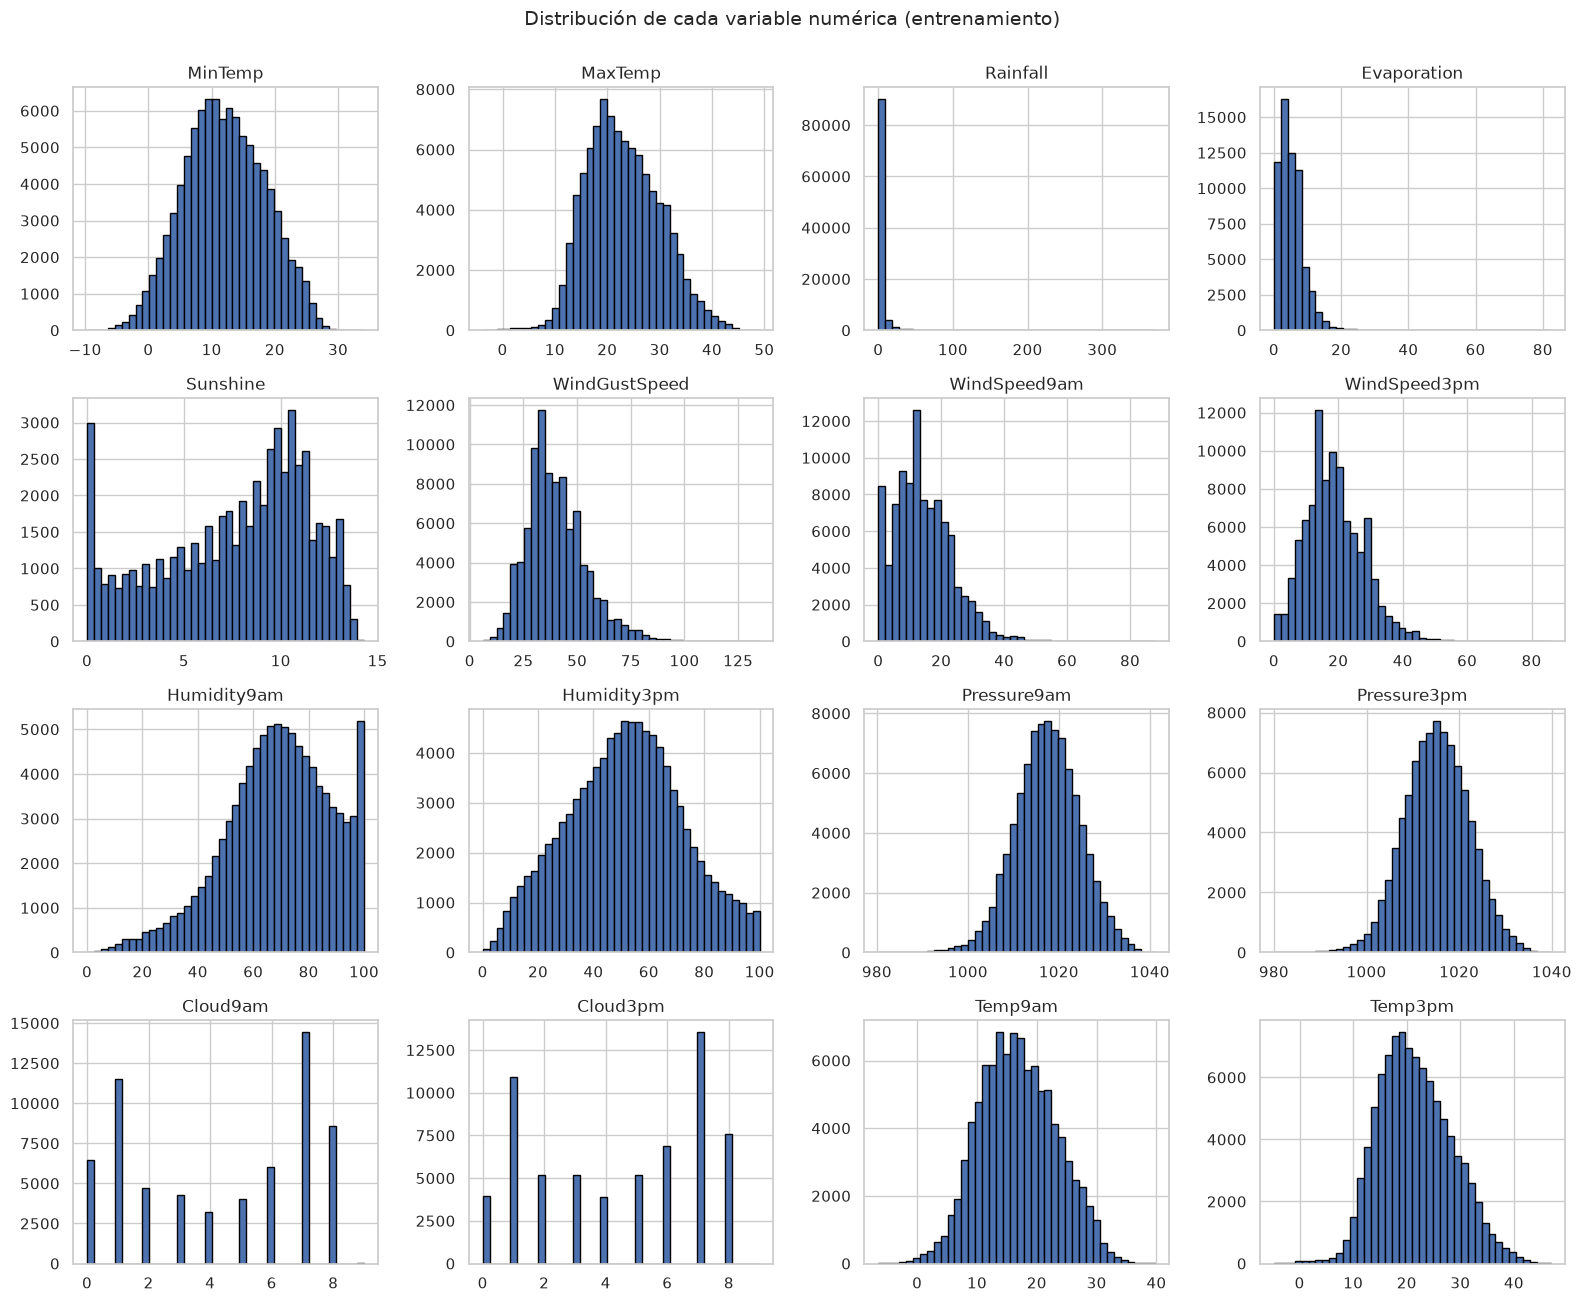

In [37]:
# Histogramas de las 16 variables numéricas para ver la forma de cada distribución
train[NUMERICAS].hist(bins=40, figsize=(16, 13), edgecolor="black", layout=(4, 4))
plt.suptitle("Distribución de cada variable numérica (entrenamiento)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 2. Histogramas de las 16 variables numéricas en entrenamiento.*

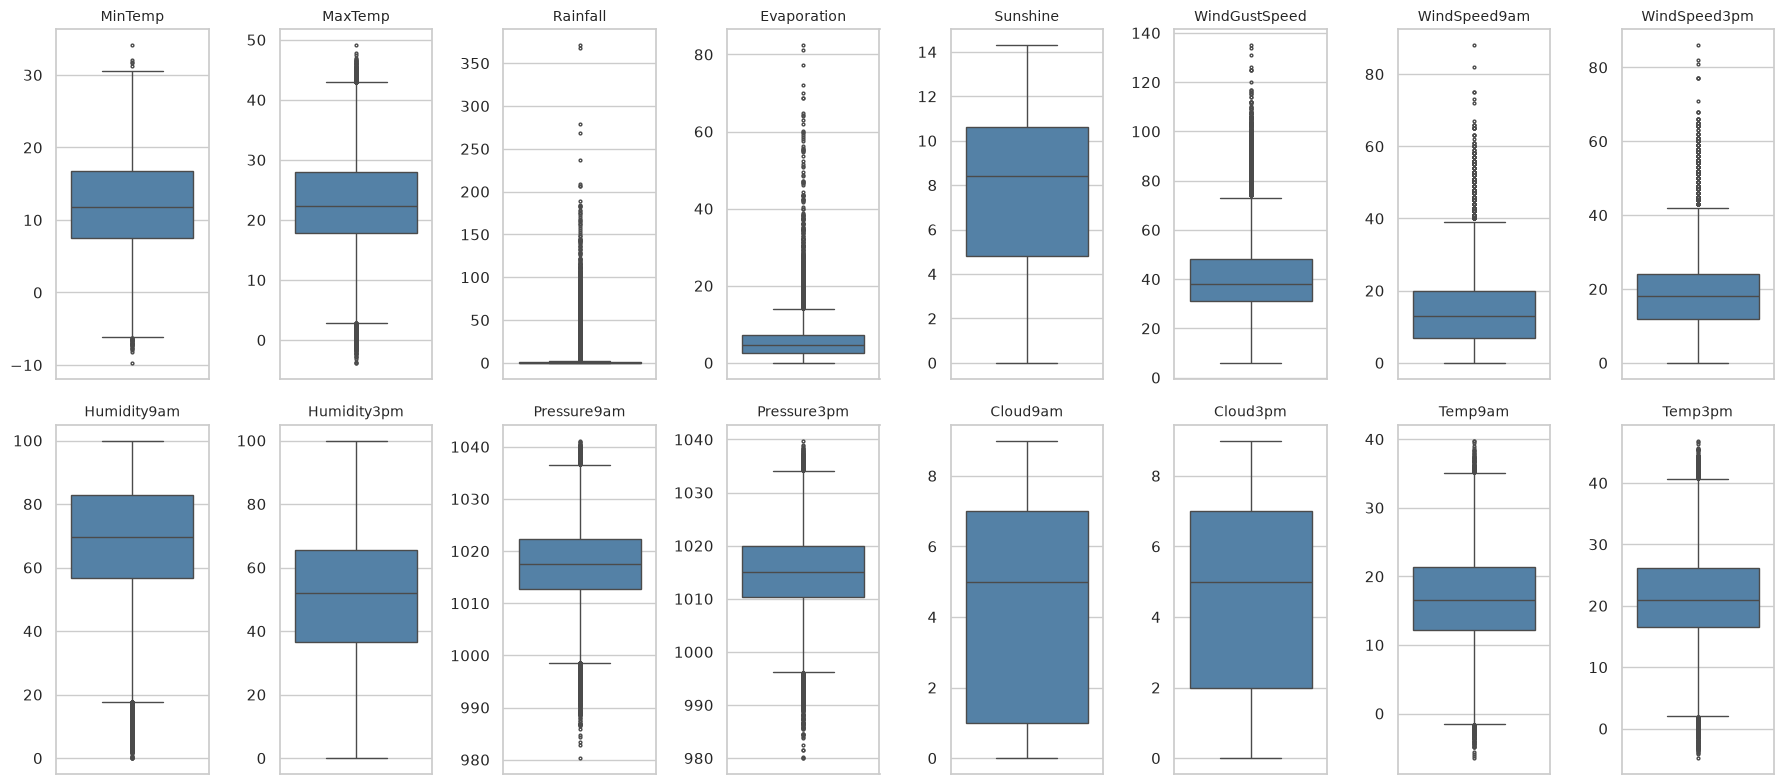

In [38]:
# Diagramas de caja de las mismas variables, para ver los valores atípicos
fig, axes = plt.subplots(2, 8, figsize=(18, 8))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.boxplot(y=train[col], ax=ax, color="steelblue", flierprops={"markersize": 2})
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

*Figura 3. Diagramas de caja de las 16 variables numéricas en entrenamiento.*

In [39]:
# Cuántos valores quedan fuera de los bigotes (Q1 − 1,5 RI y Q3 + 1,5 RI) en cada variable
q1, q3 = train[NUMERICAS].quantile(0.25), train[NUMERICAS].quantile(0.75)
ri = q3 - q1
fuera = (train[NUMERICAS] < q1 - 1.5 * ri) | (train[NUMERICAS] > q3 + 1.5 * ri)
pd.DataFrame({"atípicos": fuera.sum(), "% de los observados": (fuera.sum() / train[NUMERICAS].notna().sum() * 100).round(1),
              "Q3": q3, "mínimo": train[NUMERICAS].min(), "máximo": train[NUMERICAS].max()}).sort_values("atípicos", ascending=False)

,atípicos,% de los observados,Q3,mínimo,máximo
Rainfall,17495,18.0,0.8,0.0,371.0
WindGustSpeed,2130,2.3,48.0,6.0,135.0
Evaporation,1631,2.6,7.2,0.0,82.4
WindSpeed3pm,1199,1.2,24.0,0.0,86.0
WindSpeed9am,1090,1.1,20.0,0.0,88.0
Humidity9am,1080,1.1,82.8,0.0,100.0
Pressure9am,807,0.9,1022.3,980.3,1041.2
Pressure3pm,673,0.7,1019.9,980.0,1039.8
Temp3pm,556,0.6,26.2,-4.8,46.9
MaxTemp,414,0.4,27.9,-3.8,49.1


### Lectura de las distribuciones

Las temperaturas y las presiones tienen forma de campana (Figura 2). `Rainfall` y `Evaporation`
están apiladas contra cero con colas larguísimas. Y hay tres que no se parecen a nada simple:

- `Cloud9am` y `Cloud3pm` son bimodales, con picos en 1 y en 7 octavos: o el cielo está casi
  despejado o casi cubierto, y los valores del medio son los menos frecuentes.
- `Sunshine` tiene un pico aislado en 0 (días enteros sin sol) y el grueso entre 8 y 12 horas.
- `Humidity9am` tiene un pico en 100%, el techo de la escala.

En estas tres, un valor central como la mediana cae justo donde hay menos datos: la mediana de
`Cloud3pm` es 5, uno de los valores menos comunes. Si se completaran los faltantes con ella, miles
de filas quedarían en el valle de la distribución, y en `Sunshine` y las nubes eso es casi el 40%
de la columna.

Los diagramas de caja (Figura 3) marcan muchos atípicos, pero la regla de 1,5 veces el rango
intercuartil no le sirve a `Rainfall`: con el tercer cuartil en 0,8 mm, cualquier día de lluvia
mayor a 2 mm queda marcado como atípico, y así sale el 18% de la columna. En el resto los atípicos
no pasan el 3%, y todos son valores posibles: ráfagas de 135 km/h, mínimas de −9,7 °C, días de
cientos de milímetros de lluvia. Ninguno parece un error de carga.

No los eliminamos. Son justamente los días de tormenta, frío o viento fuerte, que el modelo tiene
que poder clasificar, y sacarlos sería entrenar y evaluar sobre una versión más fácil del problema.
Lo que sí hay que resolver es que en un modelo lineal unos pocos valores enormes pesan demasiado,
y eso se ataca con una transformación, que decidimos más abajo.

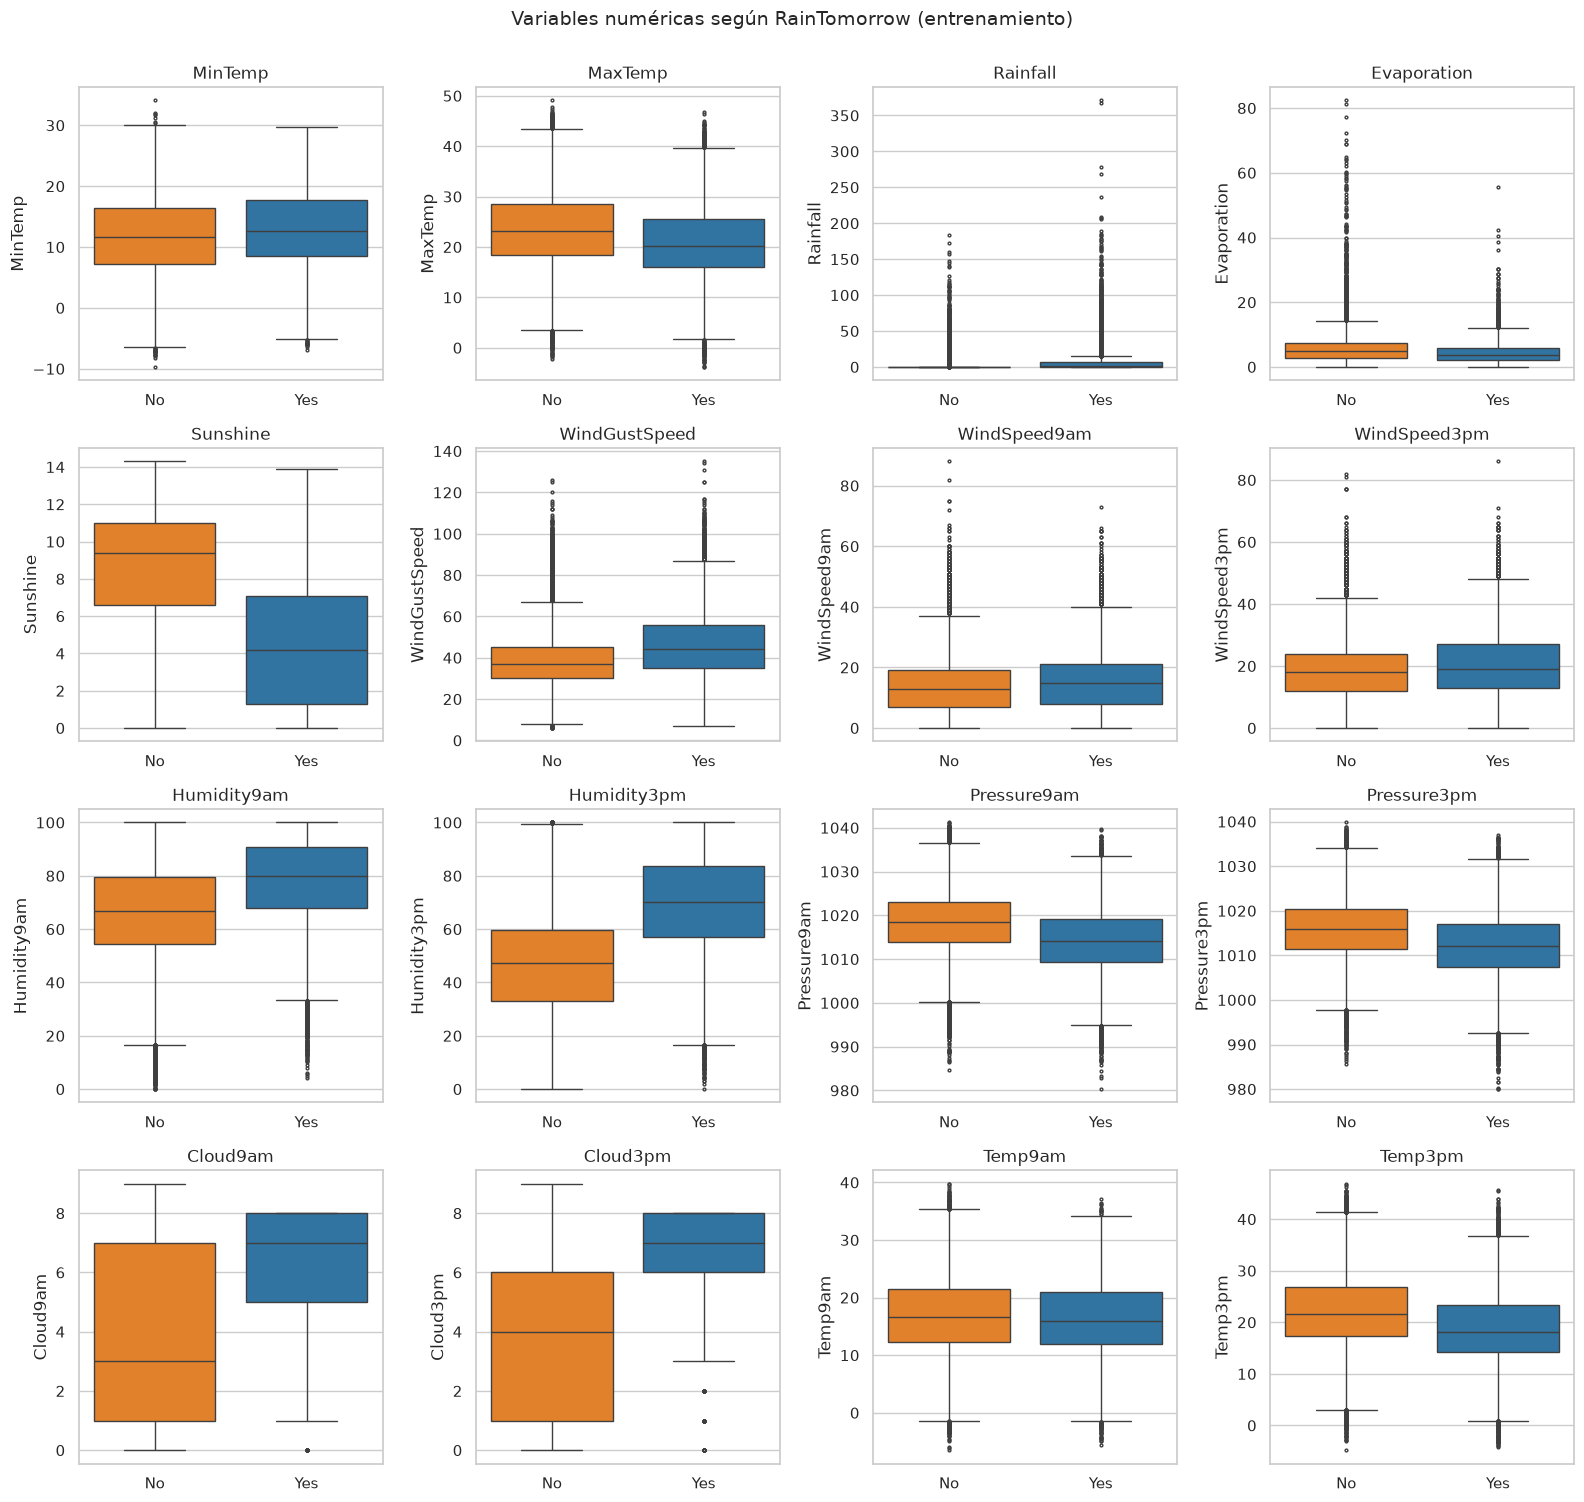

In [40]:
# Cada variable numérica separada según si al día siguiente llovió o no
fig, axes = plt.subplots(4, 4, figsize=(16, 15))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.boxplot(data=train, x="RainTomorrow", y=col, hue="RainTomorrow", palette=COLORES, ax=ax,
                legend=False, order=["No", "Yes"], flierprops={"markersize": 2})
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Variables numéricas según RainTomorrow (entrenamiento)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

*Figura 4. Diagramas de caja de cada variable numérica, separados según `RainTomorrow`, en entrenamiento.*

In [41]:
# Diferencia de medianas entre los días con y sin lluvia al día siguiente, medida en desvíos de la variable
medianas = train.groupby("RainTomorrow")[NUMERICAS].median().T
(medianas["Yes"] - medianas["No"]).div(train[NUMERICAS].std()).sort_values(key=abs, ascending=False).to_frame("diferencia en desvíos").round(2)

,diferencia en desvíos
Cloud9am,1.40
Sunshine,-1.37
Cloud3pm,1.11
Humidity3pm,1.09
Humidity9am,0.69
Pressure9am,-0.59
Pressure3pm,-0.54
Temp3pm,-0.51
WindGustSpeed,0.51
MaxTemp,-0.43


In [42]:
# RainToday contra RainTomorrow, en porcentaje de cada fila
pd.crosstab(train["RainToday"], train["RainTomorrow"], normalize="index").mul(100).round(1)

RainTomorrow,No,Yes
RainToday,,
No,84.9,15.1
Yes,53.2,46.8


### Las variables contra `RainTomorrow`

Las que más separan los días con y sin lluvia al día siguiente son las nubes, el sol y la humedad
de la tarde (Figura 4): la mediana de `Cloud9am` es 1,40 desvíos más alta en los días que preceden a
una lluvia, la de `Sunshine` 1,37 desvíos más baja, y `Cloud3pm` y `Humidity3pm` se separan más de un
desvío. Después vienen la humedad de la mañana y las presiones, más bajas antes de llover, y la
ráfaga, más fuerte. `MinTemp`, `Temp9am` y las velocidades del viento apenas se mueven.

`Rainfall` aparece casi en cero, pero porque la mediana es 0 en los dos grupos y la comparación de
medianas no la ve. La tabla cruzada sí: si hoy llovió, mañana llueve el 46,8% de las veces, y si no,
el 15,1%.

Las variables más informativas son también las que más faltan. Sacar `Sunshine` y las dos de nubes
por tener 40% de faltantes sería tirar justo las que mejor separan las clases.

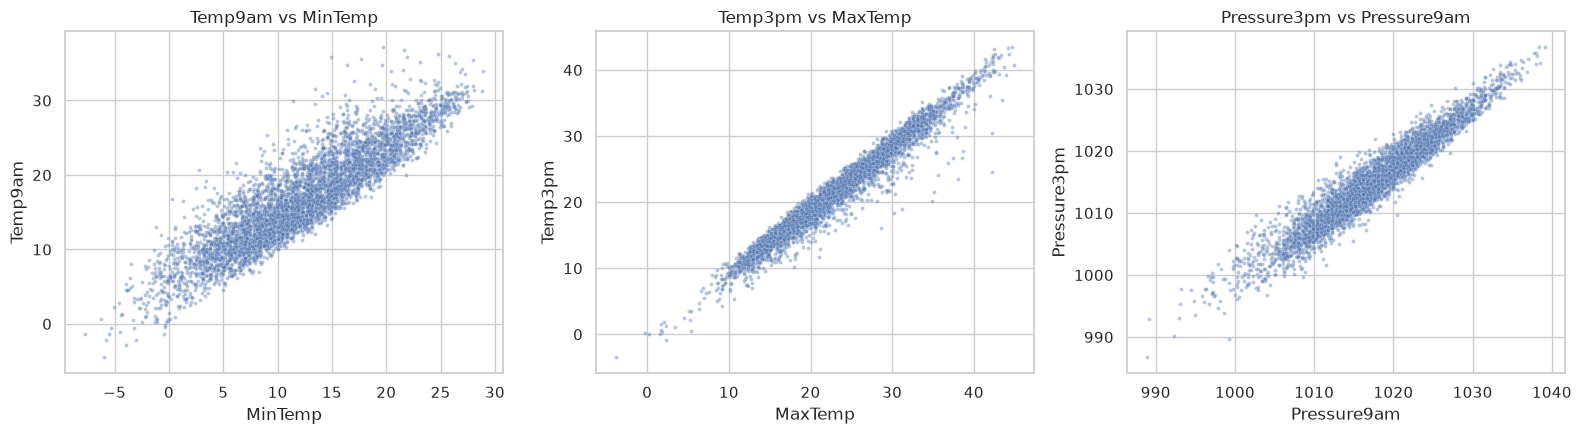

In [43]:
# Pares de variables que miden casi lo mismo en dos momentos del día
muestra = train.sample(5000, random_state=SEMILLA)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (a, b) in zip(axes, [("MinTemp", "Temp9am"), ("MaxTemp", "Temp3pm"), ("Pressure9am", "Pressure3pm")]):
    sns.scatterplot(data=muestra, x=a, y=b, ax=ax, s=8, alpha=0.4)
    ax.set_title(f"{b} vs {a}")
plt.tight_layout()
plt.show()

*Figura 5. `Temp9am` contra `MinTemp`, `Temp3pm` contra `MaxTemp` y `Pressure3pm` contra `Pressure9am`, sobre 5.000 días de entrenamiento elegidos al azar.*

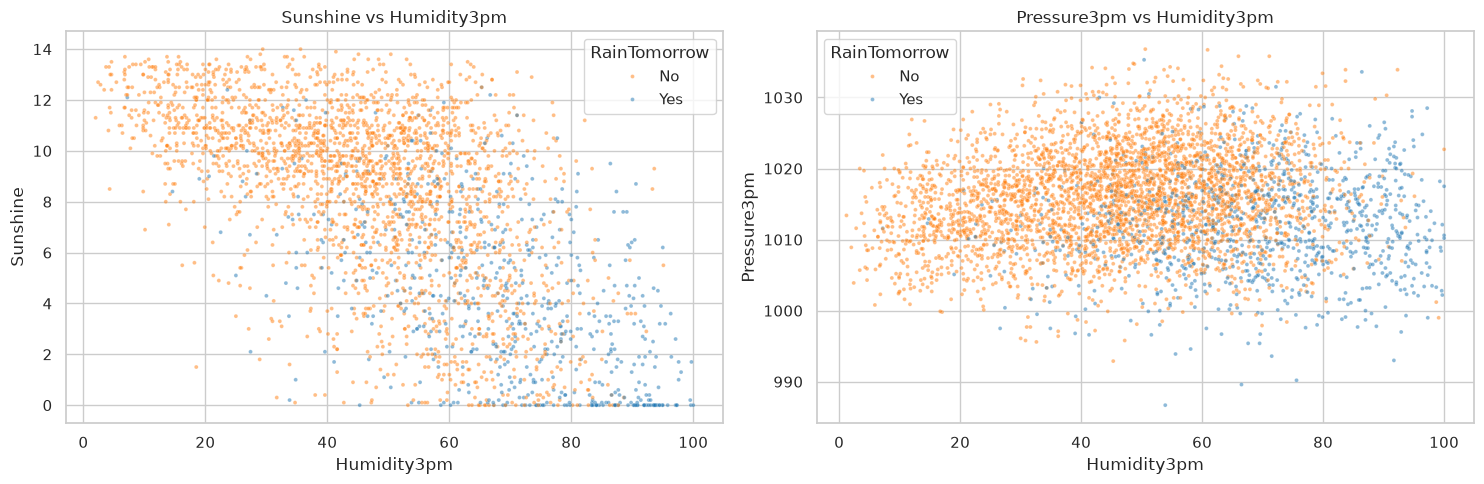

In [44]:
# Humedad de la tarde contra sol y contra presión, coloreadas según si llovió al día siguiente
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (a, b) in zip(axes, [("Humidity3pm", "Sunshine"), ("Humidity3pm", "Pressure3pm")]):
    sns.scatterplot(data=muestra, x=a, y=b, hue="RainTomorrow", hue_order=["No", "Yes"], palette=COLORES, ax=ax, s=8, alpha=0.5)
    ax.set_title(f"{b} vs {a}")
plt.tight_layout()
plt.show()

*Figura 6. `Sunshine` y `Pressure3pm` contra `Humidity3pm`, coloreados según `RainTomorrow`, sobre la misma muestra.*

Los tres pares de la Figura 5 caen sobre una diagonal angosta: la temperatura de las 9 sigue a la
mínima, la de las 15 a la máxima, y la presión de la tarde a la de la mañana. Son variables que
repiten buena parte de la información de su par, cosa que hay que tener presente para la
colinealidad. Y también para los faltantes: cuando falta una, la otra del par la predice muy bien,
mucho mejor que cualquier valor fijo.

En la Figura 6 los días previos a una lluvia se juntan abajo a la derecha: mucha humedad, poco sol,
presión baja. Ninguna de las dos variables separa sola las clases, pero la combinación las separa
bastante mejor, con una frontera que es más o menos una diagonal. Es el tipo de frontera que puede
trazar una regresión logística, que combina linealmente las variables.

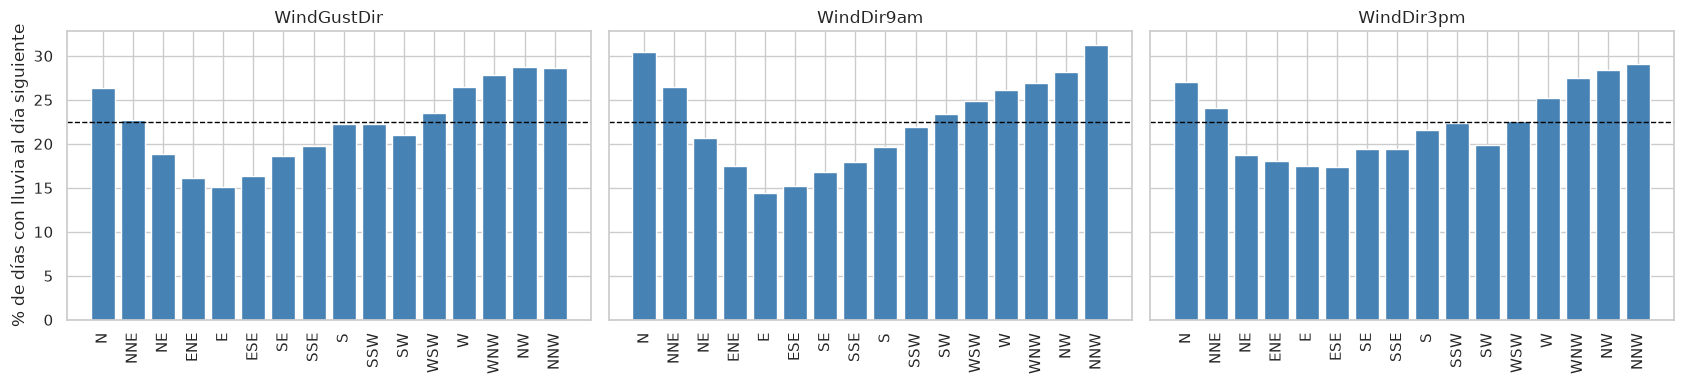

In [45]:
# Proporción de días con lluvia al día siguiente para cada dirección de viento, recorriendo la rosa de los vientos
RUMBOS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, col in zip(axes, ["WindGustDir", "WindDir9am", "WindDir3pm"]):
    proporcion = y_train.groupby(train[col]).mean().reindex(RUMBOS) * 100
    ax.bar(proporcion.index, proporcion.values, color="steelblue")
    ax.axhline(y_train.mean() * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=90)
axes[0].set_ylabel("% de días con lluvia al día siguiente")
plt.tight_layout()
plt.show()

*Figura 7. Porcentaje de días con lluvia al día siguiente según la dirección del viento, en el orden de la rosa de los vientos. La línea punteada es el promedio general.*

La lluvia cambia con la dirección del viento de forma suave a lo largo de la rosa (Figura 7): es
mínima con viento del este (alrededor del 15%) y máxima con viento del noroeste y del norte (casi
30%), y cada rumbo queda cerca de sus vecinos. Que `NNW` y `N` tengan proporciones parecidas no es
casualidad: son direcciones contiguas, y la última de la lista está pegada a la primera.

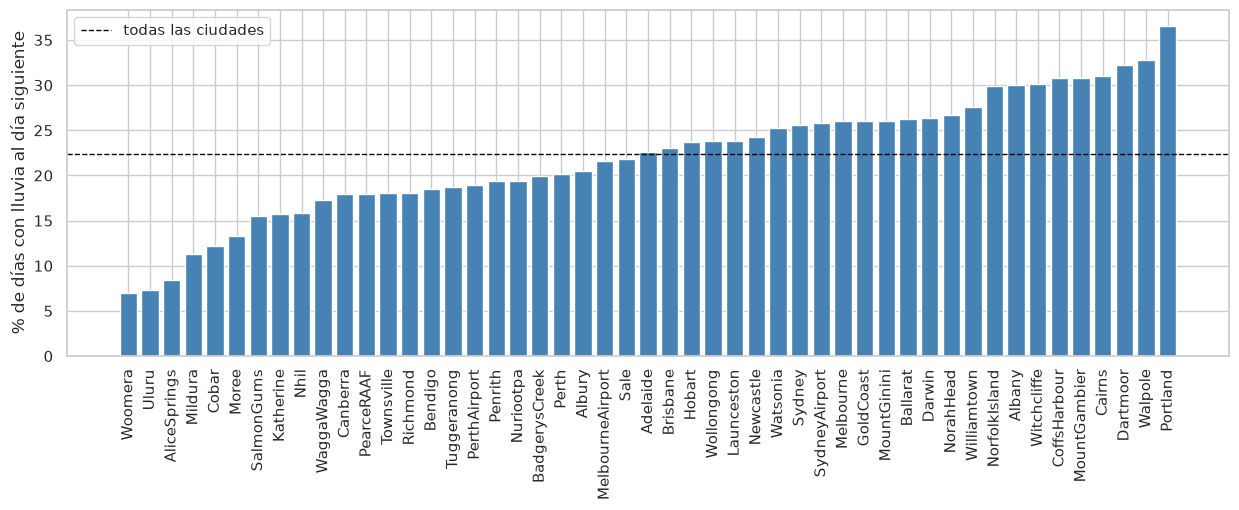

In [46]:
# Proporción de días con lluvia al día siguiente en cada ciudad
por_ciudad = y_train.groupby(train["Location"]).mean().sort_values() * 100
plt.figure(figsize=(15, 4.5))
plt.bar(por_ciudad.index, por_ciudad.values, color="steelblue")
plt.axhline(y_train.mean() * 100, color="black", linestyle="--", linewidth=1, label="todas las ciudades")
plt.xticks(rotation=90)
plt.ylabel("% de días con lluvia al día siguiente")
plt.legend()
plt.show()

*Figura 8. Porcentaje de días con lluvia al día siguiente en cada ciudad, en entrenamiento.*

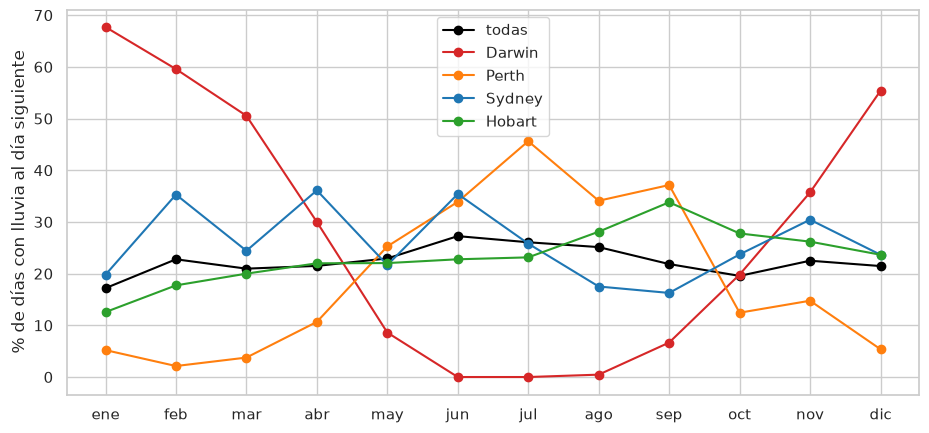

In [47]:
# Proporción de días con lluvia por mes, para todo el país y para cuatro ciudades de climas distintos
mes = train["Date"].dt.month
estacional = pd.DataFrame({"todas": y_train.groupby(mes).mean()})
for ciudad in ["Darwin", "Perth", "Sydney", "Hobart"]:
    de_la_ciudad = train["Location"] == ciudad
    estacional[ciudad] = y_train[de_la_ciudad].groupby(mes[de_la_ciudad]).mean()
estacional.mul(100).plot(marker="o", figsize=(11, 5), color=["black", "tab:red", "tab:orange", "tab:blue", "tab:green"])
plt.xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
plt.xlabel("")
plt.ylabel("% de días con lluvia al día siguiente")
plt.show()

*Figura 9. Porcentaje de días con lluvia al día siguiente por mes, en todo el país y en cuatro ciudades, en entrenamiento.*

### La ciudad y la estación

Dónde se mide cambia mucho la probabilidad de lluvia (Figura 8): en las ciudades del desierto, como
Woomera, Uluru o AliceSprings, llueve al día siguiente menos del 10% de los días, y en Portland,
Walpole, Dartmoor o Cairns, más del 30%.

La estación también, pero no igual en todas partes (Figura 9). Para el país en conjunto la curva es
casi plana, entre 17% y 27% según el mes. Esa curva promedio esconde climas opuestos: Darwin tiene
la lluvia en el verano (68% de los días en enero) y nada en el invierno (0% en junio y julio), y
Perth exactamente al revés (2% en febrero, 46% en julio). Sydney y Hobart quedan en el medio, con
menos variación.

Para el modelo esto significa que el mes, solo, informa poco, y la ciudad sola informa sólo el
promedio del año. Lo que más informa es el par: qué ciudad y en qué mes.

## Transformación de las variables con cola larga

Para decidir qué variables transformar usamos tres condiciones, y tienen que cumplirse las tres:

1. La variable no puede tener valores negativos. Como `Rainfall` y `Evaporation` valen 0 muchas
   veces, usamos log(1 + x), que en 0 da 0, en vez del logaritmo a secas.
2. Tiene que tener sesgo positivo apreciable (mayor a 0,5).
3. La transformación tiene que fortalecer la relación con `RainTomorrow`. Que una variable sea
   asimétrica no es un problema por sí mismo; lo que importa es si en la forma original los valores
   enormes aplastan la relación que el modelo tiene que aprovechar.

La decisión la tomamos con entrenamiento. Aplicar la transformación a los tres conjuntos no es
filtración: transforma cada valor por separado con una función fija, sin estimar ningún parámetro.

In [48]:
# Candidatas: sin negativos y con sesgo mayor a 0,5. Para cada una, sesgo y correlación con RainTomorrow antes y después
candidatas = [c for c in NUMERICAS if X_train[c].min() >= 0 and X_train[c].skew() > 0.5]
comparacion = pd.DataFrame({
    "sesgo": X_train[candidatas].skew(),
    "sesgo con log": np.log1p(X_train[candidatas]).skew(),
    "r con RainTomorrow": [X_train[c].corr(y_train) for c in candidatas],
    "r con log": [np.log1p(X_train[c]).corr(y_train) for c in candidatas],
})
comparacion["mejora |r|"] = comparacion["r con log"].abs() - comparacion["r con RainTomorrow"].abs()
comparacion.sort_values("mejora |r|", ascending=False).round(3)

,sesgo,sesgo con log,r con RainTomorrow,r con log,mejora |r|
Rainfall,10.088,2.040,0.243,0.349,0.106
Evaporation,3.184,-0.193,-0.126,-0.137,0.011
WindSpeed9am,0.773,-1.328,0.091,0.072,-0.019
WindGustSpeed,0.870,-0.270,0.230,0.209,-0.021
WindSpeed3pm,0.601,-1.464,0.085,0.054,-0.031


El logaritmo le corrige el sesgo a las cinco, pero la relación con `RainTomorrow` sólo mejora en dos.
En `Rainfall` la correlación sube de 0,24 a 0,34, la mejora más grande, y en `Evaporation` sube un
poco. En las tres velocidades de viento empeora: comprimir los vientos fuertes les borra justo la
diferencia que tienen con los días de lluvia. Transformamos `Rainfall` y `Evaporation`.

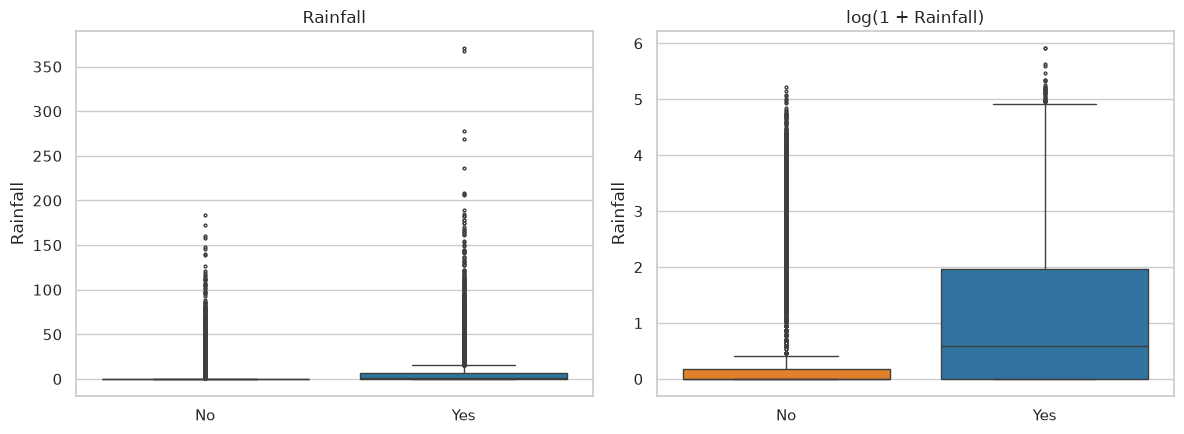

In [49]:
# Rainfall antes y después de la transformación, según RainTomorrow
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=train["RainTomorrow"], y=train["Rainfall"], hue=train["RainTomorrow"], palette=COLORES, order=["No", "Yes"],
            legend=False, ax=axes[0], flierprops={"markersize": 2})
sns.boxplot(x=train["RainTomorrow"], y=np.log1p(train["Rainfall"]), hue=train["RainTomorrow"], palette=COLORES, order=["No", "Yes"],
            legend=False, ax=axes[1], flierprops={"markersize": 2})
axes[0].set_title("Rainfall")
axes[1].set_title("log(1 + Rainfall)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

*Figura 10. `Rainfall` (izquierda) y log(1 + `Rainfall`) (derecha) según `RainTomorrow`, en entrenamiento.*

En la escala original (Figura 10, izquierda) las cajas de los dos grupos son una raya en el piso y
lo único visible son los días de cientos de milímetros. Con el logaritmo aparece la diferencia: en
los días previos a una lluvia la caja sube y deja de estar pegada a cero. Los valores extremos
siguen ahí, pero ya no están a cientos de veces la mediana.

## Codificación de variables categóricas

Las categóricas son cinco, y cada una pide algo distinto.

`RainToday` no la usamos. Es `Rainfall` cortada en 1 mm, como verificamos al principio, así que
toda su información ya está en `Rainfall`. Codificarla como 0/1 sería meter dos veces lo mismo, y en
uso podría llegar una combinación inconsistente entre las dos.

Las tres direcciones de viento son cíclicas: después de `NNW` viene otra vez `N`. Una codificación
ordinal (`N` = 0, `NNE` = 1, ..., `NNW` = 15) pondría a `N` y a `NNW` en los dos extremos de la escala,
cuando son vecinas y tienen casi la misma proporción de lluvia (Figura 7). Tampoco hay un orden que
haga monótona la relación con la lluvia, porque sube y baja a lo largo de la rosa. One-hot
funcionaría, pero son 48 columnas que no saben que `N` y `NNW` son vecinas: cada rumbo aprendería
su coeficiente por separado.

Las codificamos con seno y coseno del ángulo: cada rumbo es un punto sobre un círculo, y dos columnas
alcanzan para ubicarlo. Rumbos vecinos quedan cerca, `NNW` queda pegado a `N`, y un modelo lineal que
combina el seno y el coseno produce una curva con un máximo y un mínimo a lo largo de la rosa, que
es la forma que muestra la Figura 7. Los momentos de calma, que no tienen dirección, van al centro del
círculo (seno y coseno en 0), que está a la misma distancia de todas las direcciones. Las direcciones
que faltan por otro motivo quedan vacías y se imputan.

De la fecha usamos el mes, también con seno y coseno, para que diciembre quede al lado de enero. Solo
casi no predice la lluvia (la curva nacional de la Figura 9 es plana), pero cambia cómo se leen otras
variables: una máxima de 25 °C es un día fresco en enero y uno caluroso en julio. El día del mes no
tiene ningún significado climático.

In [50]:
# Por año en entrenamiento: proporción de días con lluvia, valores medios de Sunshine y Evaporation, y cuánto falta Sunshine
anio = X_train["Date"].dt.year
pd.DataFrame({"filas": anio.value_counts().sort_index(), "% lluvia mañana": y_train.groupby(anio).mean() * 100,
              "Sunshine media": X_train.groupby(anio)["Sunshine"].mean(), "Evaporation media": X_train.groupby(anio)["Evaporation"].mean(),
              "% Sunshine faltante": X_train["Sunshine"].isna().groupby(anio).mean() * 100}).round(2)

,filas,% lluvia mañana,Sunshine media,Evaporation media,% Sunshine faltante
Date,,,,,
2007,61,31.15,8.09,5.86,0.00
2008,2223,22.81,7.81,5.17,13.32
2009,16223,21.70,7.90,5.55,35.08
2010,16124,24.42,7.28,4.80,34.77
2011,15032,24.53,7.33,4.93,38.62
2012,14914,22.32,7.60,5.04,41.30
2013,16035,21.48,7.68,5.48,45.85
2014,17112,20.41,7.81,5.93,49.96
2015,280,16.79,9.16,9.74,52.14


El año no lo usamos. En los años completos de entrenamiento (2009 a 2014) la proporción de días con
lluvia va y viene entre 20,4% y 24,5%, sin tendencia, así que no hay un efecto del año que aprender.
Lo que sí cambia con los años es cuánto se mide `Sunshine`, que pasa de faltar en el 35% de las
filas a faltar en el 50%, mientras su valor medio se queda entre 7,3 y 7,9 horas. Esa evolución es de
los faltantes, no del clima, y la resuelve la imputación. Además, con el corte por fecha los años de
prueba no aparecen en entrenamiento: un efecto por año obligaría al modelo a extrapolar a años que
nunca vio. (2007 y 2015 tienen pocas filas en entrenamiento y no cuentan para la comparación.)

`Location` tiene 49 valores sin ningún orden entre sí, así que la codificamos con one-hot: una
columna por ciudad que vale 1 en sus filas y 0 en el resto. Cada ciudad recibe así su propio
coeficiente, que es lo que pide la Figura 8, donde la proporción de lluvia va de 7% a 36% según la
ciudad. Son 49 columnas para 98.000 filas de entrenamiento, una proporción sin problemas. Dejamos
las 49, sin descartar una como referencia, porque la regularización ya evita que el modelo quede
indeterminado y así ninguna ciudad queda escondida en la ordenada al origen. Las categorías las aprende
el codificador de entrenamiento, y una ciudad que no haya visto (como puede llegar en uso) queda con
todas las columnas en 0, que el modelo lee como "ninguna ciudad conocida".

La codificación tiene un límite. Con la ciudad y el mes como variables
separadas, un modelo lineal le suma a todas las ciudades el mismo efecto del mes, y no puede
representar a la vez la lluvia de verano de Darwin y la de invierno de Perth (Figura 9). Parte de ese
efecto puede entrar igual por las variables del día, que también cambian con la estación (las nubes,
la humedad, las temperaturas).

Las transformaciones que no aprenden nada de los datos van juntas en una función: las direcciones y
el mes a seno y coseno, la calma al centro del círculo, el logaritmo de `Rainfall` y `Evaporation`, y
sacar las columnas que no se usan. Se aplica igual a los tres conjuntos, y en uso se le aplicará igual
a cada día nuevo. La ciudad queda como texto hasta el one-hot, que sí aprende de entrenamiento y va en
el preprocesamiento final.

In [51]:
# Ángulo de cada uno de los 16 rumbos, en radianes
ANGULO = {rumbo: 2 * np.pi * i / 16 for i, rumbo in enumerate(RUMBOS)}
DIRECCIONES = {"WindGustDir": "WindGustSpeed", "WindDir9am": "WindSpeed9am", "WindDir3pm": "WindSpeed3pm"}

In [52]:
def preparar_variables(X):
    """Transformaciones fijas, sin parámetros aprendidos: seno y coseno de direcciones y mes, log de las colas largas."""
    X = X.copy()
    for direccion, velocidad in DIRECCIONES.items():
        angulo = X[direccion].map(ANGULO)
        calma = X[direccion].isna() & X[velocidad].eq(0)
        X[f"{direccion}_sen"] = np.sin(angulo).mask(calma, 0.0)
        X[f"{direccion}_cos"] = np.cos(angulo).mask(calma, 0.0)
    mes = X["Date"].dt.month
    X["mes_sen"] = np.sin(2 * np.pi * mes / 12)
    X["mes_cos"] = np.cos(2 * np.pi * mes / 12)
    X["Rainfall"] = np.log1p(X["Rainfall"])
    X["Evaporation"] = np.log1p(X["Evaporation"])
    return X.drop(columns=["Date", "RainToday", *DIRECCIONES])

In [53]:
# Aplicamos las transformaciones fijas a entrenamiento, y separamos las columnas numéricas de la ciudad
X_train_cod = preparar_variables(X_train)
NUMERICAS_COD = list(X_train_cod.columns.drop("Location"))
print(f"Columnas numéricas después de codificar: {len(NUMERICAS_COD)}")
X_train_cod.head()

Columnas numéricas después de codificar: 24


,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,WindGustDir_sen,WindGustDir_cos,WindDir9am_sen,WindDir9am_cos,WindDir3pm_sen,WindDir3pm_cos,mes_sen,mes_cos
0,Adelaide,8.4,16.0,1.791759,0.955511,2.6,46.0,14.0,15.0,90.5,67.2,1018.0,1017.9,NaN,NaN,13.8,15.6,-0.707107,7.071068e-01,-0.707107,-0.707107,-1.000000,-1.836970e-16,-0.5,-0.866025
1,Adelaide,12.3,16.1,0.587787,0.875469,7.8,36.0,14.0,16.0,75.4,52.6,1022.7,1022.6,NaN,NaN,13.8,15.1,-0.707107,-7.071068e-01,-0.382683,-0.923880,-0.707107,-7.071068e-01,-0.5,-0.866025
2,Adelaide,6.8,15.4,0.000000,1.029619,2.1,21.0,3.0,11.0,80.3,59.9,1027.7,1026.9,NaN,NaN,9.3,13.9,-1.000000,-1.836970e-16,0.382683,0.923880,-0.707107,-7.071068e-01,-0.5,-0.866025
3,Adelaide,5.1,15.4,0.000000,0.875469,8.0,30.0,9.0,13.0,72.2,47.2,1028.7,1025.7,NaN,NaN,10.1,15.9,0.382683,9.238795e-01,0.382683,0.923880,0.707107,7.071068e-01,-0.5,-0.866025
4,Adelaide,11.6,16.3,NaN,NaN,1.5,51.0,14.0,21.0,62.3,60.3,1019.3,1016.6,NaN,NaN,13.4,13.7,-0.382683,9.238795e-01,0.382683,0.923880,-0.382683,9.238795e-01,-0.5,-0.866025


In [54]:
# Chequeo de la calma: las filas con velocidad 0 y sin dirección quedaron en el centro del círculo
calmas = X_train["WindDir9am"].isna() & X_train["WindSpeed9am"].eq(0)
X_train_cod.loc[calmas, ["WindDir9am_sen", "WindDir9am_cos"]].describe().loc[["count", "min", "max"]]

,WindDir9am_sen,WindDir9am_cos
count,4160.0,4160.0
min,0.0,0.0
max,0.0,0.0


## Imputación de los faltantes

Después de codificar, lo que falta imputar son las variables numéricas y los senos y cosenos de las
direcciones que faltan por otro motivo que la calma. Comparamos tres métodos:

- **Mediana global**: cada faltante se completa con la mediana de la columna en entrenamiento. Es la
  referencia más simple.
- **Mediana por ciudad y mes**: la mediana de esa ciudad en ese mes, que es donde vimos que cambian
  las variables. Para las ciudades que nunca miden una variable no hay mediana propia, y se usa la del
  mes en todas las ciudades.
- **Regresión a partir de las otras variables del mismo día**: cada columna con faltantes se predice
  con una regresión lineal sobre todas las demás. Como las demás también tienen huecos, se arranca
  con la media y se repite el ciclo, columna por columna, usando lo ya imputado, hasta que los
  valores se estabilizan. Es lo que hace `IterativeImputer` de scikit-learn. La Figura 5 es el
  argumento a favor: si falta `Temp3pm` y está `MaxTemp`, la regresión lo aprovecha y una mediana no.

Para compararlos necesitamos saber cuánto valía cada dato que completan, y de un faltante real no lo
sabemos. Así que ocultamos valores que sí conocemos y medimos qué tan cerca queda cada método. Lo
hacemos de dos formas, porque hay dos tipos de faltantes:

- Para los huecos sueltos, ocultamos el 20% de los valores observados de cada variable, al azar.
- Para los estructurales, en cada variable que alguna estación no mide, elegimos al azar un quinto de
  las ciudades que sí la miden y le ocultamos todos sus valores, como si esa estación no tuviera el
  instrumento.

Todo con entrenamiento. El error lo medimos con la raíz del error cuadrático medio (RMSE), en las
unidades de cada variable, y lo comparamos con su desvío: un método que no sabe nada y completa
siempre con el mismo valor central tiene un RMSE parecido al desvío.

In [55]:
# El imputador por regresión todavía es experimental en scikit-learn y hay que habilitarlo antes de importarlo
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer

In [56]:
# Columnas con faltantes después de codificar, y las variables con ciudades que nunca las miden
A_IMPUTAR = [c for c in NUMERICAS_COD if X_train_cod[c].isna().any()]
ESTRUCTURALES = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm", "Pressure9am", "Pressure3pm", "WindGustSpeed"]
print(f"Columnas a imputar ({len(A_IMPUTAR)}): {A_IMPUTAR}")

Columnas a imputar (22): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'WindGustDir_sen', 'WindGustDir_cos', 'WindDir9am_sen', 'WindDir9am_cos', 'WindDir3pm_sen', 'WindDir3pm_cos']


In [57]:
# Ocultamos el 20% de los valores observados de cada columna, al azar
rng = np.random.default_rng(SEMILLA)
oculto_azar = X_train_cod[A_IMPUTAR].notna() & (rng.random((len(X_train_cod), len(A_IMPUTAR))) < 0.2)

In [58]:
# Y para cada variable estructural, todos los valores de un quinto de las ciudades que la miden
oculto_ciudad = pd.DataFrame(False, index=X_train_cod.index, columns=A_IMPUTAR)
medidas = X_train_cod[ESTRUCTURALES].notna().groupby(X_train["Location"]).mean()
for col in ESTRUCTURALES:
    la_miden = medidas.index[medidas[col] > 0.8]
    elegidas = rng.choice(la_miden, size=len(la_miden) // 5, replace=False)
    oculto_ciudad[col] = X_train["Location"].isin(elegidas) & X_train_cod[col].notna()
    print(f"{col}: ocultamos {', '.join(elegidas)}")

Sunshine: ocultamos Brisbane, NorfolkIsland, Albany, Portland, Moree
Evaporation: ocultamos Sale, MelbourneAirport, Watsonia, Dartmoor, CoffsHarbour
Cloud9am: ocultamos Canberra, Katherine, MelbourneAirport, SydneyAirport, Townsville
Cloud3pm: ocultamos Sale, MountGambier, Portland, MelbourneAirport, SydneyAirport
Pressure9am: ocultamos Cairns, Darwin, Wollongong, Ballarat, SydneyAirport, BadgerysCreek, Canberra, Adelaide, Woomera
Pressure3pm: ocultamos Uluru, BadgerysCreek, Nhil, AliceSprings, Dartmoor, Bendigo, Melbourne, PearceRAAF, Wollongong
WindGustSpeed: ocultamos Sale, AliceSprings, Katherine, WaggaWagga, Nhil, Cobar, CoffsHarbour, Uluru, Bendigo


In [59]:
# Las columnas numéricas de entrenamiento con los valores ocultos, sin tocar el original
X_oculto = X_train_cod[NUMERICAS_COD].copy()
X_oculto[A_IMPUTAR] = X_oculto[A_IMPUTAR].mask(oculto_azar | oculto_ciudad)

In [60]:
def mediana_por_ciudad_y_mes(X_codificado, X_original):
    """Completa con la mediana del par ciudad-mes y, si no existe, con la del mes en todas las ciudades."""
    grupos_ciudad_mes = [X_original["Location"], X_original["Date"].dt.month]
    por_ciudad_mes = X_codificado.groupby(grupos_ciudad_mes).transform("median")
    por_mes = X_codificado.groupby(X_original["Date"].dt.month).transform("median")
    return X_codificado.fillna(por_ciudad_mes).fillna(por_mes)

In [61]:
# Imputamos el conjunto con valores ocultos con cada uno de los tres métodos
imputados = {}
imputados["mediana global"] = SimpleImputer(strategy="median").set_output(transform="pandas").fit_transform(X_oculto)
imputados["mediana por ciudad y mes"] = mediana_por_ciudad_y_mes(X_oculto, X_train)
imputados["regresión"] = IterativeImputer(max_iter=20, random_state=SEMILLA).set_output(transform="pandas").fit_transform(X_oculto)

In [62]:
def rmse_ocultos(oculto):
    """RMSE de cada método sobre los valores ocultos, y el desvío de cada variable como referencia."""
    tabla = pd.DataFrame({metodo: [np.sqrt(((X_imp.loc[oculto[c], c] - X_train_cod.loc[oculto[c], c]) ** 2).mean()) for c in oculto.columns]
                          for metodo, X_imp in imputados.items()}, index=oculto.columns)
    tabla["desvío"] = X_train_cod[oculto.columns].std()
    return tabla.round(2)

In [63]:
# Error sobre los huecos sueltos
rmse_ocultos(oculto_azar[A_IMPUTAR])

,mediana global,mediana por ciudad y mes,regresión,desvío
MinTemp,6.35,3.24,2.69,6.36
MaxTemp,7.04,3.75,1.82,6.99
Rainfall,1.02,0.97,0.90,0.91
Evaporation,0.60,0.40,0.41,0.59
Sunshine,3.89,3.57,2.55,3.79
WindGustSpeed,13.93,12.79,10.01,13.73
WindSpeed9am,9.15,7.96,7.77,9.01
WindSpeed3pm,9.05,8.08,7.76,8.93
Humidity9am,19.13,14.90,12.15,19.04
Humidity3pm,20.84,15.90,11.07,20.79


In [64]:
# Error sobre las ciudades enteras ocultas
rmse_ocultos(oculto_ciudad[ESTRUCTURALES])

,mediana global,mediana por ciudad y mes,regresión,desvío
Sunshine,3.91,3.83,2.66,3.79
Evaporation,0.63,0.48,0.42,0.59
Cloud9am,2.83,2.82,2.26,2.87
Cloud3pm,2.50,2.55,2.18,2.69
Pressure9am,6.98,6.38,3.79,7.07
Pressure3pm,7.13,6.46,4.08,7.00
WindGustSpeed,13.03,12.42,10.16,13.73


La regresión tiene el menor error en casi todas las variables y en los dos escenarios.

En los huecos sueltos, la mediana global tiene un error igual al desvío en todas las variables:
completar con un valor fijo no aporta nada. La mediana por ciudad y mes mejora mucho las
temperaturas, que dependen de la estación, y casi nada el sol, las nubes y la presión, que cambian
de un día a otro dentro del mismo mes. La regresión mejora a casi todas, y a algunas por mucho: al
imputar `Temp3pm` el error baja de 6,85 °C con la mediana global a 1,77 °C, y en las presiones de
unos 7 hPa a menos de 4, porque cada una tiene un par que la predice (Figura 5). Las excepciones son
`Evaporation` y el seno de `WindDir9am`, donde la mediana por ciudad y mes queda igual o apenas
mejor (0,40 contra 0,41 y 0,63 contra 0,67).

En las ciudades ocultas la ventaja se mantiene. Como el RMSE queda en las unidades de la variable,
el de `Sunshine` se lee en horas de sol: la regresión erra por 2,66 horas en promedio y la mediana
por ciudad y mes por 3,83, casi lo mismo que el desvío. Ahí esa mediana ya no puede usar la ciudad,
que es justamente la que falta, y cae en la mediana del mes; la regresión sigue teniendo las otras
variables de ese mismo día.

El error no es lo único que importa. Un método puede acertar en promedio y aun así deformar la
distribución, y el modelo aprende de la distribución entera. Lo miramos en las variables con más
faltantes.

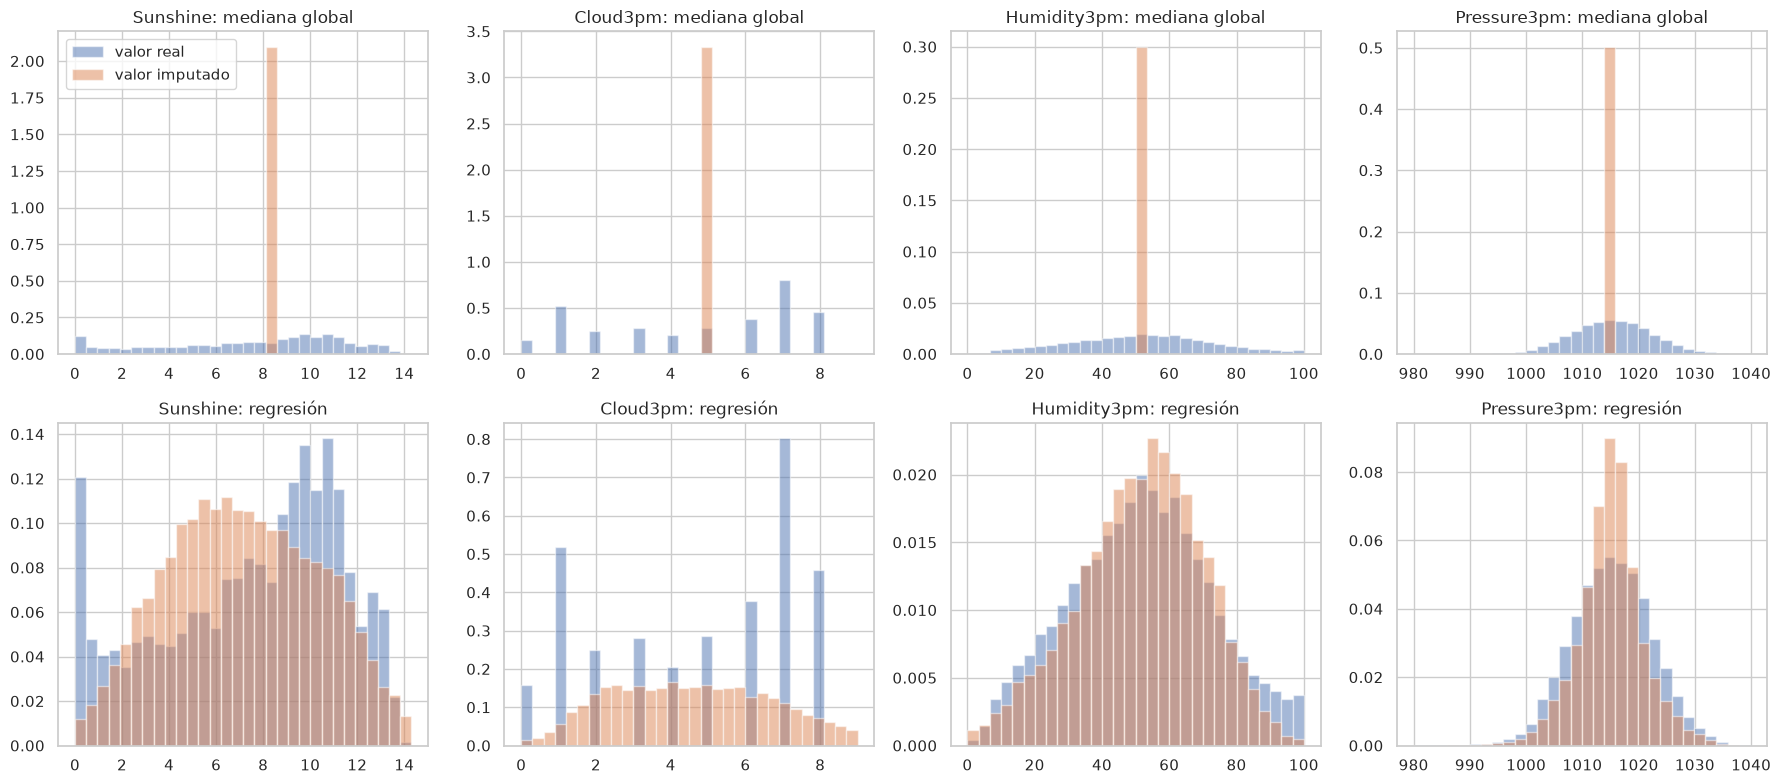

In [65]:
# Distribución de los valores observados contra la de los valores imputados, para cuatro variables y dos métodos
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for fila, metodo in enumerate(["mediana global", "regresión"]):
    for ax, col in zip(axes[fila], ["Sunshine", "Cloud3pm", "Humidity3pm", "Pressure3pm"]):
        oculto = oculto_azar[col] | oculto_ciudad[col]
        bins = np.histogram_bin_edges(X_train_cod[col].dropna(), bins=30)
        ax.hist(X_train_cod.loc[oculto, col], bins=bins, density=True, alpha=0.5, label="valor real")
        ax.hist(imputados[metodo].loc[oculto, col], bins=bins, density=True, alpha=0.5, label="valor imputado")
        ax.set_title(f"{col}: {metodo}")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

*Figura 11. Distribución de los valores reales ocultos contra la de los valores que les asignó cada método, para la mediana global (arriba) y la regresión (abajo), en cuatro variables.*

In [66]:
# Desvío de cada columna completa, después de imputar, relativo al de los valores observados
pd.DataFrame({metodo: X_imp[A_IMPUTAR].std() / X_train_cod[A_IMPUTAR].std() for metodo, X_imp in imputados.items()}).round(2)

,mediana global,mediana por ciudad y mes,regresión
MinTemp,0.89,0.98,0.99
MaxTemp,0.89,0.97,0.99
Rainfall,0.92,0.92,0.96
Evaporation,0.65,0.84,0.93
Sunshine,0.64,0.73,0.90
WindGustSpeed,0.81,0.83,0.97
WindSpeed9am,0.89,0.93,0.96
WindSpeed3pm,0.89,0.92,0.97
Humidity9am,0.89,0.95,0.99
Humidity3pm,0.89,0.95,0.98


La mediana global pone todos los faltantes en un único valor (Figura 11, arriba): una barra sola
donde antes había una distribución entera. En `Cloud3pm` esa barra cae en 5, el valle entre los dos
picos, y en `Sunshine` en el medio de una distribución que tiene un pico en 0. El desvío de las
columnas completas lo confirma: con la mediana global, `Sunshine` y las nubes pierden un tercio de su
desvío (les queda entre 0,64 y 0,68 del original), porque el 40% de la columna queda en un solo
punto. Con la regresión conservan entre 0,85 y 0,90.

La regresión (Figura 11, abajo) reparte los valores imputados a lo largo del rango. En
`Humidity3pm` y `Pressure3pm` la distribución imputada se superpone casi entera con la real. En
`Sunshine` y `Cloud3pm` no: la regresión predice valores medios, así que no reproduce los picos de los
extremos (los días sin sol, el cielo casi despejado o casi cubierto) y amontona los valores en el
centro. Es una deformación real, pero mucho menor que la de la mediana, que concentra todo en un
punto.

Imputamos con regresión. El costo es que no es un método trivial de explicar, y que en
scikit-learn todavía figura como experimental. Le agregamos dos cosas:

- Límites: cada columna imputada se recorta al mínimo y al máximo que tuvo en entrenamiento, para que
  la regresión no invente horas de sol negativas o humedades de más de 100%.
- Redondeo de la nubosidad: `Cloud9am` y `Cloud3pm` se miden en octavos enteros, y la regresión les
  asigna valores como 4,3. Los redondeamos al octavo más cercano para que la variable conserve su
  escala. Eso no recupera los dos picos de la distribución, pero evita que el modelo vea valores que
  ninguna estación puede registrar.

## Matriz de correlación

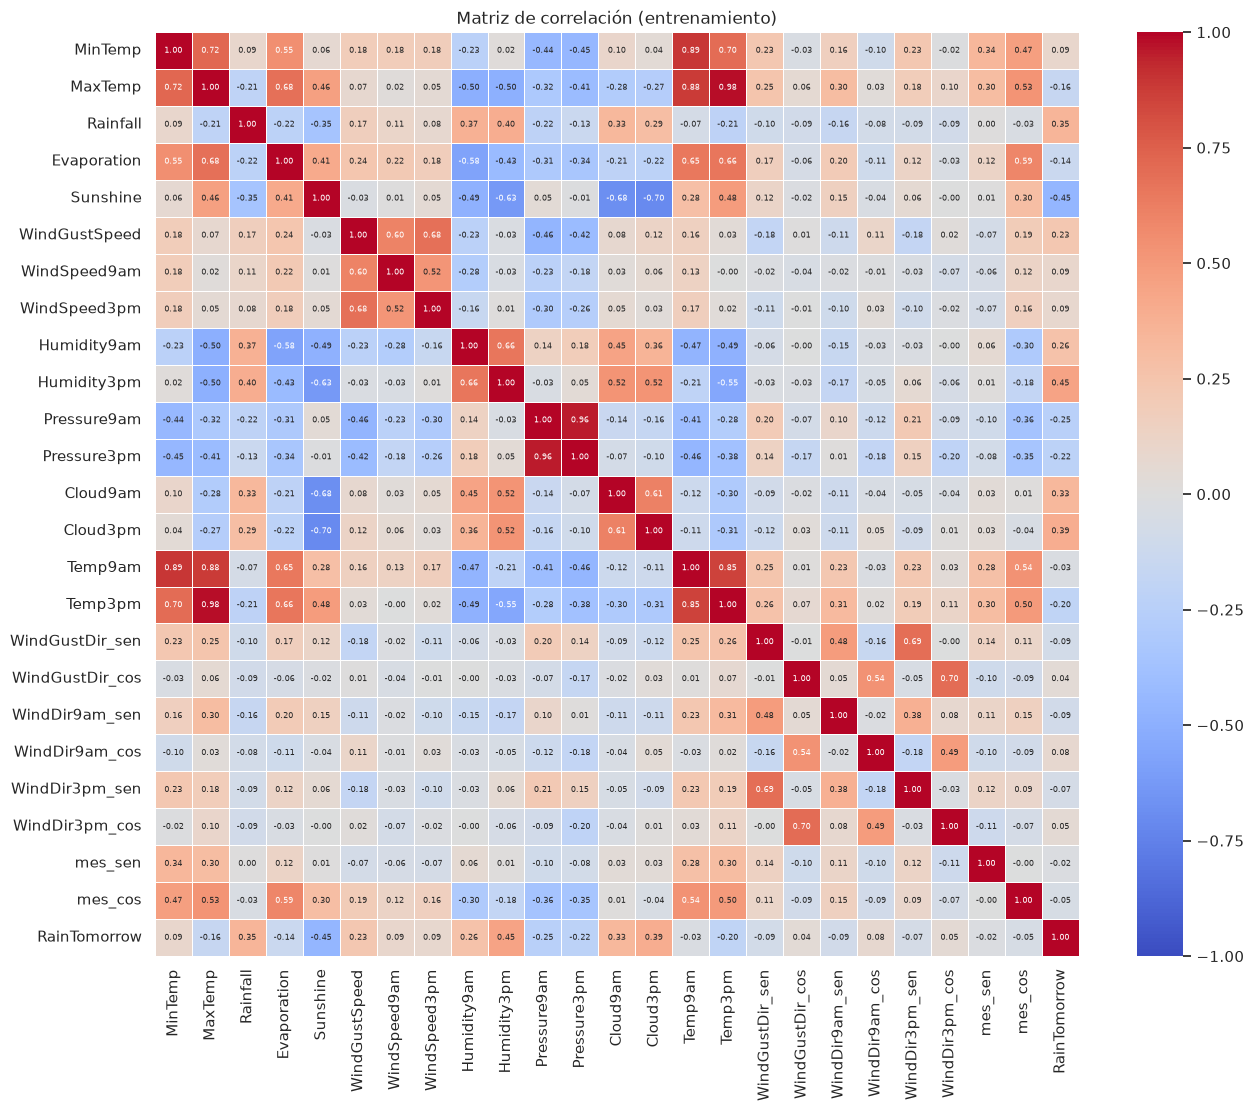

In [67]:
# Matriz de correlación de Pearson sobre entrenamiento codificado, antes de imputar, con la variable a predecir
correlacion = X_train_cod[NUMERICAS_COD].assign(RainTomorrow=y_train).corr()
plt.figure(figsize=(15, 12))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 6})
plt.title("Matriz de correlación (entrenamiento)")
plt.show()

*Figura 12. Matriz de correlación de Pearson entre las variables numéricas codificadas y `RainTomorrow`, calculada sobre entrenamiento antes de imputar.*

In [68]:
# Correlación de cada variable con RainTomorrow, ordenada por valor absoluto
correlacion["RainTomorrow"].drop("RainTomorrow").sort_values(key=abs, ascending=False).to_frame("r con RainTomorrow").round(3)

,r con RainTomorrow
Sunshine,-0.454
Humidity3pm,0.448
Cloud3pm,0.392
Rainfall,0.349
Cloud9am,0.328
Humidity9am,0.260
Pressure9am,-0.246
WindGustSpeed,0.230
Pressure3pm,-0.224
Temp3pm,-0.196


In [69]:
# Pares de variables con correlación mayor a 0,7 en valor absoluto
import itertools

pares = [(a, b, correlacion.loc[a, b]) for a, b in itertools.combinations(NUMERICAS_COD, 2) if abs(correlacion.loc[a, b]) > 0.7]
pd.DataFrame(pares, columns=["variable A", "variable B", "correlación"]).sort_values("correlación", key=abs, ascending=False).round(3)

,variable A,variable B,correlación
3,MaxTemp,Temp3pm,0.979
5,Pressure9am,Pressure3pm,0.959
1,MinTemp,Temp9am,0.894
2,MaxTemp,Temp9am,0.879
6,Temp9am,Temp3pm,0.852
0,MinTemp,MaxTemp,0.724
4,Sunshine,Cloud3pm,-0.703
7,WindGustDir_cos,WindDir3pm_cos,0.701


La calculamos antes de imputar, con los pares de valores observados, para que la imputación no la
contamine: la regresión imputa justamente a partir de estas correlaciones y las reforzaría. Las 49
columnas de la ciudad no entran: cada una sólo indica si la fila es de esa ciudad, y su relación con
la lluvia ya la muestra la Figura 8.

Las más correlacionadas con `RainTomorrow` (Figura 12) son `Sunshine` (−0,454), `Humidity3pm`
(0,448), `Cloud3pm` (0,392), `Rainfall` en logaritmo (0,349) y `Cloud9am` (0,328): las mismas que
separaban las clases en la Figura 4. Los senos y cosenos de las direcciones y del mes tienen
correlaciones chicas, menores a 0,1, y es lo esperable: cada uno por separado es sólo una proyección
del ángulo, y la relación con la lluvia aparece al combinarlos.

Entre las características hay pares muy correlacionados, todos explicables por lo que miden.
`MaxTemp` y `Temp3pm` (0,979) y las dos presiones (0,959) son casi la misma variable, y las
temperaturas en general forman un bloque (`MinTemp` con `Temp9am` 0,894, `MaxTemp` con `Temp9am`
0,879). Fuera de ese bloque están `Sunshine` con `Cloud3pm` (−0,703), más nubes y menos sol, y los
cosenos de la ráfaga y del viento de la tarde (0,701), que suelen venir del mismo lado.

Las dejamos todas. La colinealidad no impide ajustar el modelo, pero vuelve inestables los
coeficientes de las variables involucradas, que pueden repartirse el peso de varias formas casi
equivalentes. Sacar una de cada par a mano sería decidir de forma arbitraria cuál importa, cuando
la regularización ataca justamente ese problema: al penalizar el tamaño de los coeficientes, el peso
se reparte entre las variables redundantes en vez de crecer en una a costa de la otra.

## Escalado de los datos

Estandarizamos: a cada variable numérica le restamos su media y la dividimos por su desvío. La
regresión logística se ajusta con un método iterativo que converge mal cuando las escalas son
dispares, y la regularización, que es su hiperparámetro principal, penaliza el tamaño de los
coeficientes: sin escalar castigaría más a las variables de valores chicos sólo por la unidad en la
que están medidas. Los senos y cosenos, que ya están entre −1 y 1, también se escalan; el cambio es
cosmético pero así no hay columnas numéricas tratadas aparte.

Elegimos estandarizar y no llevar al rango [0, 1] porque el mínimo y el máximo los fijan los valores
extremos, que decidimos conservar: con `WindSpeed9am` llegando a 88 km/h y la mediana en 13, casi
todos los días quedarían apretados en el primer quinto del rango.

El escalador va después de imputar, para que la media y el desvío se calculen sobre la columna tal
como entra al modelo. Las 49 columnas de la ciudad no se escalan: valen 0 o 1, ya están en una escala
comparable con el resto, y así se siguen leyendo como "es esta ciudad o no".

## Preprocesamiento completo

Juntamos todos los pasos en un solo `Pipeline`. Primero las transformaciones fijas; después, por un
lado las columnas numéricas (imputación, redondeo de la nubosidad y escalado) y por otro la ciudad
(one-hot). Así se ajusta una sola vez con entrenamiento, se aplica idéntico a validación y prueba, y
es el mismo objeto que va a recibir los días nuevos cuando el modelo esté en uso.

In [70]:
def redondear_nubosidad(X):
    """Lleva la nubosidad imputada al octavo entero más cercano."""
    X = X.copy()
    X[["Cloud9am", "Cloud3pm"]] = X[["Cloud9am", "Cloud3pm"]].round()
    return X

In [71]:
# Los pasos del preprocesamiento: transformaciones fijas, y después numéricas y ciudad por separado
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

numericas = Pipeline([
    ("imputacion", IterativeImputer(max_iter=20, random_state=SEMILLA,
                                    min_value=X_train_cod[NUMERICAS_COD].min().to_numpy(),
                                    max_value=X_train_cod[NUMERICAS_COD].max().to_numpy())),
    ("redondeo_nubosidad", FunctionTransformer(redondear_nubosidad, feature_names_out="one-to-one")),
    ("escalado", StandardScaler()),
])
preprocesamiento = Pipeline([
    ("transformaciones_fijas", FunctionTransformer(preparar_variables)),
    ("columnas", ColumnTransformer([("numericas", numericas, NUMERICAS_COD),
                                    ("ciudad", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Location"])],
                                   verbose_feature_names_out=False)),
]).set_output(transform="pandas")

In [72]:
# Ajustamos con entrenamiento y a validación y prueba sólo les aplicamos lo ya ajustado
X_train_prep = preprocesamiento.fit_transform(X_train, y_train)
X_val_prep = preprocesamiento.transform(X_val)
X_test_prep = preprocesamiento.transform(X_test)
print(f"Entrenamiento: {X_train_prep.shape}  |  Validación: {X_val_prep.shape}  |  Prueba: {X_test_prep.shape}")
print(f"Faltantes que quedan: {int(X_train_prep.isna().sum().sum() + X_val_prep.isna().sum().sum() + X_test_prep.isna().sum().sum())}")

Entrenamiento: (98004, 73)  |  Validación: (14016, 73)  |  Prueba: (28048, 73)
Faltantes que quedan: 0


In [73]:
# La nubosidad quedó en octavos enteros y cada fila tiene exactamente una ciudad
CIUDADES = [c for c in X_train_prep.columns if c.startswith("Location_")]
print(f"Valores distintos de Cloud3pm en entrenamiento: {X_train_prep['Cloud3pm'].nunique()}")
print(f"Columnas de ciudad: {len(CIUDADES)}  |  Filas de entrenamiento con una sola ciudad: {X_train_prep[CIUDADES].sum(axis=1).eq(1).mean():.0%}")

Valores distintos de Cloud3pm en entrenamiento: 10
Columnas de ciudad: 49  |  Filas de entrenamiento con una sola ciudad: 100%


In [74]:
# Media y desvío de cada columna numérica en los tres conjuntos: entrenamiento tiene que dar 0 y 1, los otros dos no
pd.DataFrame({"media train": X_train_prep[NUMERICAS_COD].mean(), "desvío train": X_train_prep[NUMERICAS_COD].std(),
              "media val": X_val_prep[NUMERICAS_COD].mean(), "desvío val": X_val_prep[NUMERICAS_COD].std(),
              "media test": X_test_prep[NUMERICAS_COD].mean(), "desvío test": X_test_prep[NUMERICAS_COD].std()}).round(3)

,media train,desvío train,media val,desvío val,media test,desvío test
MinTemp,0.0,1.0,-0.104,1.027,0.171,1.016
MaxTemp,0.0,1.0,-0.092,1.042,0.177,1.056
Rainfall,0.0,1.0,-0.036,0.948,-0.002,1.004
Evaporation,0.0,1.0,-0.110,0.989,0.138,0.998
Sunshine,-0.0,1.0,-0.075,0.956,-0.013,0.977
WindGustSpeed,-0.0,1.0,-0.092,0.958,-0.018,0.981
WindSpeed9am,0.0,1.0,-0.060,0.966,-0.013,0.948
WindSpeed3pm,0.0,1.0,-0.075,0.979,-0.034,0.963
Humidity9am,-0.0,1.0,0.083,1.017,0.004,1.008
Humidity3pm,0.0,1.0,0.021,0.988,-0.002,1.012


La nubosidad quedó en valores enteros: `Cloud3pm` toma 10 valores distintos en entrenamiento, los
octavos de 0 a 8 más el 9 que ya venía en el archivo. Y cada fila tiene exactamente una ciudad en 1.

La tabla confirma que no hubo filtración. Entrenamiento queda con media 0 y desvío 1 en todas las
columnas numéricas, porque es el conjunto con el que se calcularon esos parámetros (los −0,0 son
ceros redondeados). Validación y prueba no dan 0 y 1: se transformaron con la media y el desvío de
entrenamiento, sin que sus propios datos entraran en el cálculo. Si los tres conjuntos dieran 0 y 1,
sería señal de que escalamos todo junto.

Las diferencias son del tiempo, no del escalado. Los senos y cosenos del mes se apartan porque
validación cubre de enero a octubre de 2015 y prueba de noviembre de 2015 a junio de 2017, así que
no tienen los meses en las mismas proporciones que los siete años de entrenamiento. Las presiones de
validación quedan 0,33 desvíos arriba y las temperaturas de prueba 0,17; con estos datos no podemos
separar cuánto se debe a los meses que cubre cada conjunto y cuánto a que esos años fueron
distintos. Es el tipo de corrimiento que el modelo va a encontrar en uso.

# Regresión logística

## Clase positiva y costo de los errores

La clase positiva es la lluvia: `RainTomorrow` = 1. Con eso, los dos errores posibles son:

- Falso positivo: el modelo avisa que llueve y no llueve. Es una falsa alarma: alguien lleva paraguas
  de más o suspende algo que podía hacerse.
- Falso negativo: el modelo dice que no llueve y llueve. Nadie se preparó.

El falso negativo es peor. El modelo existe para avisar de la lluvia, y un aviso que falta deja a quien
lo usa sin margen para reaccionar; una falsa alarma tiene un costo, pero acotado. Por eso la accuracy no
sirve para elegir entre modelos: predecir siempre "No" ya da 77,6% sin detectar un solo día de lluvia.
Lo primero que miramos es el recall de la lluvia: de los días que llovió, cuántos detectó el modelo.

Pero el recall solo no alcanza como criterio, porque un modelo que avisa lluvia todos los días tiene
recall 1 y no le sirve a nadie. Lo acompaña la precisión (de los avisos de lluvia, cuántos acertaron), y
fijamos de antemano cómo se combinan: el umbral se elige para maximizar el recall de la lluvia con la
condición de que la precisión no baje de 0,5. Con ese piso, cuando el modelo avisa lluvia es más
probable que llueva a que no, y se aceptan como mucho una falsa alarma por cada aviso correcto, que ya
es bastante tolerancia del lado del error barato. Avisar siempre daría una precisión de 0,22, así que
el piso le exige al aviso más del doble. Descartamos usar el F1 como criterio porque pesa igual un
falso negativo que un falso positivo, y acabamos de decidir que no valen lo mismo.

## Primer modelo

Usamos `LogisticRegression` con sus valores por defecto: regularización L2 con `C` = 1, optimizada con
`lbfgs`. Elegir `C` es una búsqueda de hiperparámetros y queda para más adelante; acá interesa qué da el
modelo sin ajustar nada. Que haya regularización desde el principio es lo que nos permitió dejar las
variables correlacionadas.

Entrenamos sobre `X_train_prep`, que ya pasó por el preprocesamiento ajustado con entrenamiento. Meter
el preprocesamiento y el modelo en otro `Pipeline` daría el mismo resultado, pero repitiendo la
imputación, que es el paso más lento.

Probamos dos versiones. Una tal cual, y otra con `class_weight="balanced"`, que en la función de costo
multiplica el error de cada fila por un peso inversamente proporcional a la frecuencia de su clase. Así
el modelo ya no puede bajar el costo total sacrificando los días de lluvia, que es el riesgo que
señalamos al ver el desbalance, y lo hace sin agregar ni sacar filas. Las alternativas eran esas:

- Oversampling: repetir filas de lluvia. Equivale a subirles el peso, pero ocupando más memoria, y el
  modelo ve muchas veces los mismos días.
- SMOTE: generar días de lluvia nuevos interpolando entre vecinos. Supone que el punto medio entre dos
  días de lluvia también es un día de lluvia, y con las 49 columnas de ciudad, que valen 0 o 1, ese
  punto medio sería una fila con media Sydney y media Perth.
- Undersampling: descartar días secos. Es tirar observaciones reales cuando el problema no es la
  cantidad de datos.

In [75]:
# Peso que recibe un error en cada clase con class_weight="balanced"
from sklearn.utils.class_weight import compute_class_weight

pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
print(f"Día seco: {pesos[0]:.2f}  |  Día de lluvia: {pesos[1]:.2f}  |  Razón: {pesos[1] / pesos[0]:.2f}")

Día seco: 0.64  |  Día de lluvia: 2.23  |  Razón: 3.46


In [76]:
# Entrenamos los dos modelos y verificamos que el optimizador haya convergido
from sklearn.linear_model import LogisticRegression

modelos = {"sin balanceo": LogisticRegression(), "balanceado": LogisticRegression(class_weight="balanced")}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_prep, y_train)
    print(f"{nombre}: convergió en {modelo.n_iter_[0]} de {modelo.max_iter} iteraciones")

sin balanceo: convergió en 57 de 100 iteraciones


balanceado: convergió en 62 de 100 iteraciones


En el modelo balanceado, un error en un día de lluvia pesa 3,46 veces lo que uno en un día seco, que es
la razón entre las dos clases en entrenamiento (77,6% contra 22,4%). Los dos modelos convergen bien antes
del límite de 100 iteraciones, así que no hace falta subirlo.

## Métricas con el umbral 0,5

Además de accuracy, precisión, recall y F1, calculamos dos métricas que no dependen del umbral:

- El AUC, el área bajo la curva ROC. Mide qué tan bien ordena el modelo los días: es la probabilidad de
  que, tomando al azar un día de lluvia y uno seco, el modelo le asigne más probabilidad al de lluvia.
  0,5 es azar y 1 es perfecto.
- La log loss, que es la entropía cruzada binaria: la misma función que el modelo minimiza al
  entrenar. Mide qué tan buenas son las probabilidades en sí, no sólo de qué lado del umbral caen, y
  castiga mucho asignarle una probabilidad baja a algo que pasó. Cuanto más baja, mejor.

Precisión, recall y F1 son los de la clase lluvia. Calculamos todo en entrenamiento y en validación;
prueba no se mira hasta tener el modelo y el umbral elegidos.

In [77]:
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score

def metricas(y, probabilidad, umbral=0.5):
    """Métricas de la clase lluvia para un umbral dado, más el AUC y la log loss, que no dependen de él."""
    prediccion = (probabilidad >= umbral).astype(int)
    return {"accuracy": accuracy_score(y, prediccion), "precisión": precision_score(y, prediccion),
            "recall": recall_score(y, prediccion), "F1": f1_score(y, prediccion),
            "AUC": roc_auc_score(y, probabilidad), "log loss": log_loss(y, probabilidad)}

In [78]:
# Métricas de los dos modelos en entrenamiento y validación, con el umbral 0,5
conjuntos_prep = {"entrenamiento": (X_train_prep, y_train), "validación": (X_val_prep, y_val)}
pd.DataFrame({(nombre, conjunto): metricas(yc, modelo.predict_proba(Xc)[:, 1])
              for nombre, modelo in modelos.items() for conjunto, (Xc, yc) in conjuntos_prep.items()}).T.round(3)

accuracy  precisión  recall     F1    AUC  log loss
sin balanceo entrenamiento     0.852      0.735   0.533  0.618  0.878     0.343
             validación        0.854      0.746   0.497  0.596  0.877     0.341
balanceado   entrenamiento     0.800      0.537   0.785  0.638  0.879     0.436
             validación        0.809      0.543   0.754  0.632  0.877     0.417

In [79]:
# Probabilidad media de lluvia que asigna cada modelo en validación, contra la proporción real
print(f"Proporción real de días con lluvia: {y_val.mean():.3f}")
for nombre, modelo in modelos.items():
    print(f"{nombre}: {modelo.predict_proba(X_val_prep)[:, 1].mean():.3f}")

Proporción real de días con lluvia: 0.218
sin balanceo: 0.207
balanceado: 0.359


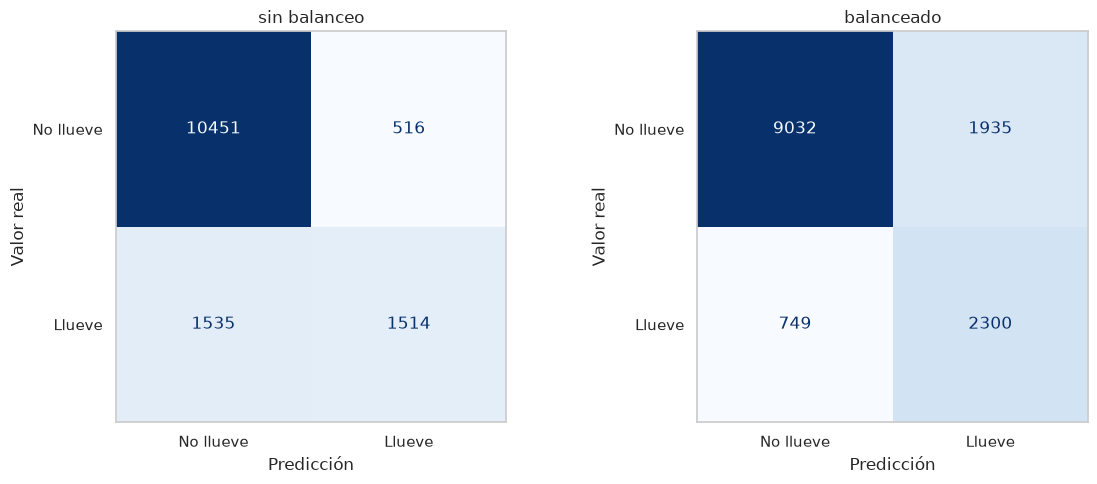

In [80]:
# Matrices de confusión de los dos modelos en validación, con el umbral 0,5
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_val_prep, y_val, display_labels=["No llueve", "Llueve"],
                                          cmap="Blues", values_format="d", colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
plt.tight_layout()
plt.show()

*Figura 13. Matrices de confusión de la regresión logística sin balanceo (izquierda) y balanceada (derecha), en validación, con el umbral 0,5.*

Con el umbral 0,5, el modelo sin balanceo tiene la mejor accuracy (0,854, contra 0,776 de predecir
siempre "No"), pero detecta sólo la mitad de los días de lluvia: el recall es 0,497, y en la Figura 13
son 1.535 días en los que llovió sin aviso, contra 1.514 detectados. Es justo el error que más nos
importa. El modelo balanceado reduce esos falsos negativos a la mitad (749) y sube el recall a 0,754, a
cambio de casi cuadruplicar las falsas alarmas (de 516 a 1.935): su precisión baja a 0,543.

El AUC, en cambio, es el mismo en los dos modelos (0,877). Los pesos no hicieron que el modelo distinga
mejor los días de lluvia de los secos; lo que cambió es a partir de qué probabilidad dice "lluvia". Eso
hace sospechar que balancear tiene casi el mismo efecto que bajar el umbral del modelo sin balanceo.

Lo que sí distingue a los dos es la calidad de las probabilidades. El modelo sin balanceo asigna en
promedio 0,207 de probabilidad de lluvia, cerca del 0,218 real, así que sus probabilidades se pueden
leer como tales. El balanceado asigna 0,359: al pesar más la lluvia infla todas las probabilidades, y por
eso su log loss es peor (0,417 contra 0,341).

## Curva ROC

Cada punto de la curva es un umbral: la tasa de verdaderos positivos (el recall) contra la tasa de falsos
positivos (las falsas alarmas sobre el total de días secos) que se obtienen cortando ahí. La calculamos en
validación, porque el umbral es una decisión y prueba no se usa para decidir. Marcamos el punto que
corresponde al umbral 0,5 en cada modelo.

In [81]:
# Probabilidad de lluvia que asigna cada modelo a los días de validación
prob_val = {nombre: modelo.predict_proba(X_val_prep)[:, 1] for nombre, modelo in modelos.items()}
COLORES_MODELO = {"sin balanceo": "tab:green", "balanceado": "tab:purple"}

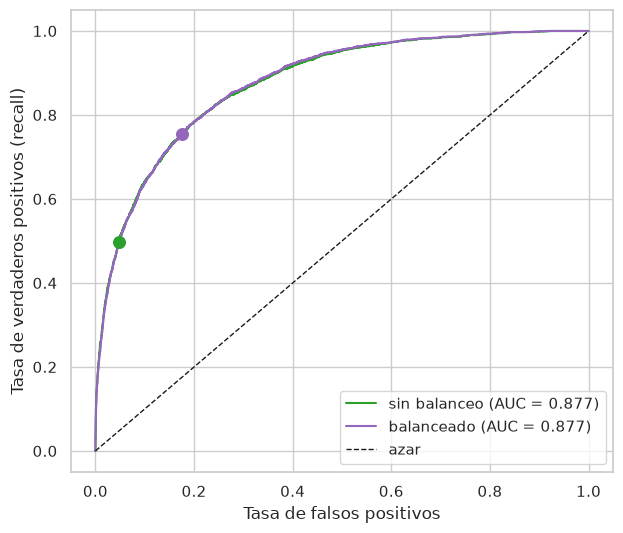

In [82]:
# Curvas ROC de los dos modelos en validación, con el punto del umbral 0,5
from sklearn.metrics import confusion_matrix, roc_curve

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, probabilidad in prob_val.items():
    fpr, tpr, _ = roc_curve(y_val, probabilidad)
    ax.plot(fpr, tpr, color=COLORES_MODELO[nombre], label=f"{nombre} (AUC = {roc_auc_score(y_val, probabilidad):.3f})")
    vn, fp, fn, vp = confusion_matrix(y_val, probabilidad >= 0.5).ravel()
    ax.scatter(fp / (fp + vn), vp / (vp + fn), color=COLORES_MODELO[nombre], s=70, zorder=3)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.legend(loc="lower right")
plt.show()

*Figura 14. Curvas ROC de la regresión logística sin balanceo y balanceada, en validación. Los puntos marcan el umbral 0,5 de cada modelo.*

Las dos curvas están una encima de la otra (Figura 14): para cada tasa de falsas alarmas, los dos modelos
detectan la misma proporción de días de lluvia. Lo que las diferencia es dónde cae el umbral 0,5. En el
modelo sin balanceo cae abajo a la izquierda, con pocas falsas alarmas y la mitad de las lluvias
detectadas; en el balanceado, más arriba y a la derecha sobre la misma curva. Balancear movió el punto
de corte, no la curva.

## Elección del umbral

Aplicamos el criterio fijado al principio: entre los umbrales que dejan la precisión en 0,5 o más, el que
da mayor recall. Recorremos los umbrales de 0,05 a 0,95 de a 0,01, en validación.

Lo comparamos con otro criterio, que sale de la propia curva: el umbral cuyo punto queda más cerca de la
esquina superior izquierda, donde estaría un modelo que detecta todas las lluvias sin ninguna falsa alarma.
Ese criterio no sabe que nos importa más un error que el otro, así que sirve de control: si los dos
eligen umbrales muy distintos, la elección depende del criterio más que de los datos.

In [83]:
def barrido_umbrales(y, probabilidad):
    """Precisión y recall de la clase lluvia para cada umbral entre 0,05 y 0,95."""
    umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
    return pd.DataFrame({"precisión": [precision_score(y, probabilidad >= u) for u in umbrales],
                         "recall": [recall_score(y, probabilidad >= u) for u in umbrales]},
                        index=pd.Index(umbrales, name="umbral"))

In [84]:
# Umbral elegido con el criterio (máximo recall con precisión de al menos 0,5) y umbral más cercano a la esquina de la ROC
barridos = {nombre: barrido_umbrales(y_val, probabilidad) for nombre, probabilidad in prob_val.items()}
umbral_elegido = {nombre: float(barrido.loc[barrido["precisión"] >= 0.5, "recall"].idxmax()) for nombre, barrido in barridos.items()}
umbral_esquina = {}
for nombre, probabilidad in prob_val.items():
    fpr, tpr, umbrales = roc_curve(y_val, probabilidad)
    umbral_esquina[nombre] = float(umbrales[np.hypot(fpr, 1 - tpr).argmin()])
print(f"Umbral elegido: {umbral_elegido}  |  Umbral más cercano a la esquina: { {n: round(u, 3) for n, u in umbral_esquina.items()} }")

Umbral elegido: {'sin balanceo': 0.18, 'balanceado': 0.43}  |  Umbral más cercano a la esquina: {'sin balanceo': 0.196, 'balanceado': 0.454}


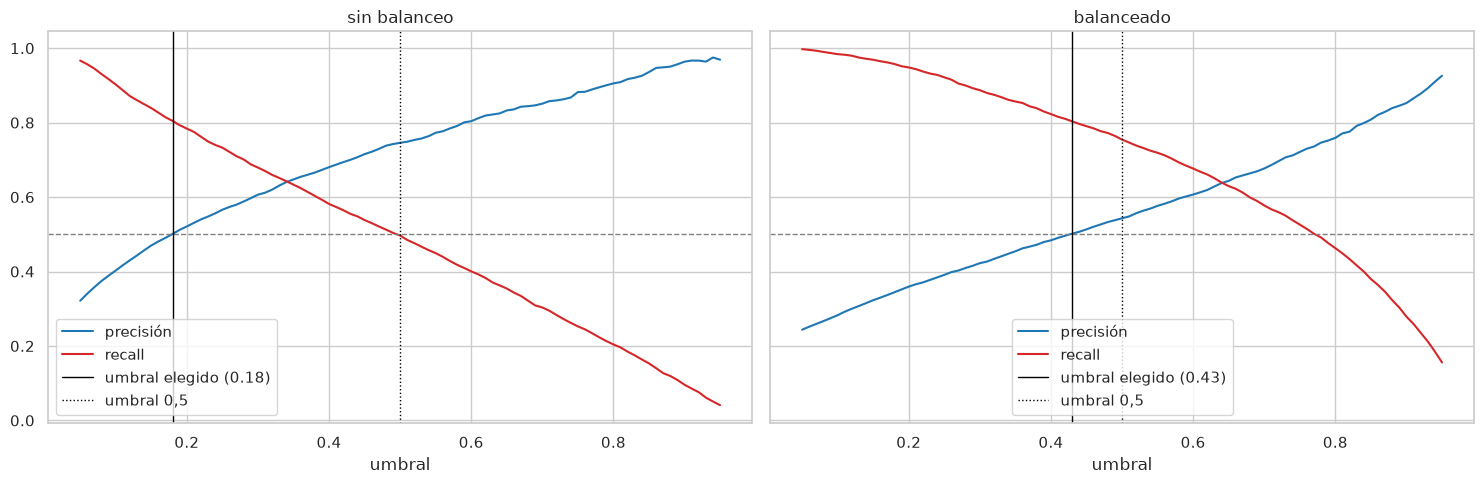

In [85]:
# Precisión y recall según el umbral, con el piso de precisión y el umbral elegido de cada modelo
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (nombre, barrido) in zip(axes, barridos.items()):
    barrido.plot(ax=ax, color=["tab:blue", "tab:red"])
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.axvline(umbral_elegido[nombre], color="black", linewidth=1, label=f"umbral elegido ({umbral_elegido[nombre]})")
    ax.axvline(0.5, color="black", linestyle=":", linewidth=1, label="umbral 0,5")
    ax.set_title(nombre)
    ax.legend()
plt.tight_layout()
plt.show()

*Figura 15. Precisión y recall de la clase lluvia en validación según el umbral, para el modelo sin balanceo (izquierda) y el balanceado (derecha). La línea gris punteada es el piso de precisión de 0,5.*

In [86]:
def resumen_umbral(y, probabilidad, umbral):
    """Precisión, recall, F1 y cantidad de falsos negativos y falsos positivos de la clase lluvia para un umbral."""
    prediccion = probabilidad >= umbral
    vn, fp, fn, vp = confusion_matrix(y, prediccion).ravel()
    return {"umbral": round(float(umbral), 3), "precisión": precision_score(y, prediccion), "recall": recall_score(y, prediccion),
            "F1": f1_score(y, prediccion), "falsos negativos": fn, "falsos positivos": fp}

In [87]:
# Cada modelo con el umbral 0,5, el elegido y el más cercano a la esquina, en validación
filas = {(nombre, criterio): resumen_umbral(y_val, prob_val[nombre], umbral)
         for nombre in modelos
         for criterio, umbral in [("0,5", 0.5), ("elegido", umbral_elegido[nombre]), ("esquina ROC", umbral_esquina[nombre])]}
pd.DataFrame.from_dict(filas, orient="index").round(3)

umbral  precisión  recall     F1  falsos negativos  falsos positivos
sin balanceo 0,5           0.500      0.746   0.497  0.596              1535               516
             elegido       0.180      0.501   0.805  0.617               596              2443
             esquina ROC   0.196      0.518   0.788  0.625               646              2236
balanceado   0,5           0.500      0.543   0.754  0.632               749              1935
             elegido       0.430      0.502   0.803  0.618               600              2432
             esquina ROC   0.454      0.517   0.789  0.625               644              2247

Con el criterio, el umbral queda en 0,18 para el modelo sin balanceo y en 0,43 para el balanceado: en los
dos es el punto donde la precisión toca el piso de 0,5 (Figura 15). Por debajo de ese punto el recall
seguiría subiendo, pero la precisión ya no cumple la condición.

El umbral 0,5 no es el mejor para lo que buscamos. En el modelo sin balanceo, bajarlo a 0,18 lleva los
falsos negativos de 1.535 a 596: de cada 100 días de lluvia avisa en 80 en vez de en 50. El precio es
pasar de 516 a 2.443 falsas alarmas, dentro de lo que el piso de precisión acepta. Que el umbral tenga
que bajar tanto es consecuencia del desbalance: si llueve en el 22% de los días, un día al que el modelo
le da 30% de probabilidad ya es más lluvioso que el promedio, y con el umbral 0,5 no se avisa.

Cada modelo con su umbral queda prácticamente igual al otro: 596 y 600 falsos negativos, 2.443 y 2.432
falsas alarmas. Eso confirma lo que sugerían el AUC y la Figura 14: con la regresión logística, balancear
las clases equivale a bajar el umbral del modelo sin balanceo.

El control da lo mismo. El umbral más cercano a la esquina de la ROC es 0,196 en un modelo y 0,454 en
el otro, al lado de los elegidos, con un recall de 0,79 en vez de 0,80. Dos criterios distintos llegan
al mismo lugar, así que la elección no depende de cuál se use.

El umbral elegido tiene un límite: es el más bajo que cumple el piso, y deja la precisión de validación
en 0,501, justo encima de 0,5. En días que el modelo no vio la precisión puede quedar un poco por debajo.

## Elección del modelo

In [88]:
# Los dos modelos con su umbral elegido, junto con la calidad de sus probabilidades, en validación
pd.DataFrame.from_dict({nombre: {**resumen_umbral(y_val, prob_val[nombre], umbral_elegido[nombre]),
                                 "log loss": log_loss(y_val, prob_val[nombre]),
                                 "probabilidad media": prob_val[nombre].mean(), "proporción real": y_val.mean()}
                        for nombre in modelos}, orient="index").round(3)

,umbral,precisión,recall,F1,falsos negativos,falsos positivos,log loss,probabilidad media,proporción real
sin balanceo,0.18,0.501,0.805,0.617,596,2443,0.341,0.207,0.218
balanceado,0.43,0.502,0.803,0.618,600,2432,0.417,0.359,0.218


Con su umbral, los dos modelos detectan las mismas lluvias y dan las mismas falsas alarmas, así que la
elección no sale de la matriz de confusión. Sale de las probabilidades. En validación llueve el 21,8% de
los días; el modelo sin balanceo asigna en promedio 0,207 de probabilidad de lluvia y el balanceado
0,359, con una log loss peor (0,417 contra 0,341). Las probabilidades del modelo sin balanceo
coinciden en promedio con la frecuencia real de la lluvia, y las del balanceado están infladas por los
pesos. Eso importa para quien use el modelo, que puede querer la probabilidad además del sí o el no, y
para interpretar qué variables la mueven.

Nos quedamos con la regresión logística sin balanceo y umbral 0,18. Balancear no aporta nada que el
umbral no dé: es una segunda modificación que hace lo mismo que la primera, y descalibra las
probabilidades.

El umbral queda en 0,18 aunque deje la precisión justo en el borde del piso. Correrlo a 0,20, cerca del
umbral de la esquina, daría algo de margen, pero sería mover el criterio después de ver dónde cae, que es
lo que fijarlo de antemano buscaba evitar. Si en datos nuevos la precisión queda por debajo de 0,5, lo va
a mostrar la evaluación en prueba.

In [89]:
# El modelo y el umbral elegidos
modelo_elegido = modelos["sin balanceo"]
umbral = umbral_elegido["sin balanceo"]

## Ajuste del modelo

Comparamos el modelo elegido en entrenamiento y en validación, con el umbral 0,18. Si rindiera mucho
mejor en entrenamiento, habría aprendido particularidades de esos días que no se repiten (sobreajuste).
Si rindiera parecido en los dos pero poco, el límite estaría en el modelo (subajuste).

In [90]:
# Métricas del modelo elegido en entrenamiento y validación, con el umbral elegido
pd.DataFrame({conjunto: metricas(yc, modelo_elegido.predict_proba(Xc)[:, 1], umbral)
              for conjunto, (Xc, yc) in conjuntos_prep.items()}).T.round(3)

,accuracy,precisión,recall,F1,AUC,log loss
entrenamiento,0.773,0.496,0.830,0.621,0.878,0.343
validación,0.783,0.501,0.805,0.617,0.877,0.341


In [91]:
# Con mucha menos regularización (C = 100), ¿el modelo se ajusta mejor a entrenamiento?
poco_regularizado = LogisticRegression(C=100, max_iter=1000).fit(X_train_prep, y_train)
pd.DataFrame({f"C = {modelo.C:g}": {conjunto: roc_auc_score(yc, modelo.predict_proba(Xc)[:, 1])
                                  for conjunto, (Xc, yc) in conjuntos_prep.items()}
              for modelo in [modelo_elegido, poco_regularizado]}).round(4).rename_axis("AUC")

,C = 1,C = 100
AUC,,
entrenamiento,0.8783,0.8782
validación,0.8766,0.8766


No hay sobreajuste. Entrenamiento y validación dan casi lo mismo en todo: AUC 0,878 y 0,877, log loss
0,343 y 0,341, recall 0,830 y 0,805. Con 98.004 filas y 73 columnas, el modelo tiene muchos más datos
que coeficientes, y no le alcanza para memorizar días.

Tampoco es un ajuste perfecto, y el límite no está en la regularización. Con `C` = 100, que penaliza
cien veces menos el tamaño de los coeficientes, el AUC en entrenamiento queda igual (0,878): aun con
libertad para ajustarse más a los datos que ve, no lo hace. Lo que lo frena es la forma del modelo. La
regresión logística separa las clases con un hiperplano, y ya vimos casos que eso no puede representar,
como la lluvia de verano de Darwin y la de invierno de Perth con la ciudad y el mes como variables
separadas. Es un modelo con algo de sesgo y muy poca varianza: generaliza bien, y lo que no aprende no lo
aprendería tampoco con más libertad. Mejorarlo pide un modelo capaz de fronteras no lineales, no
ajustar más este.

## Evaluación en prueba

Es la única vez que miramos prueba, con el modelo y el umbral ya fijados. Nada de lo que salga acá cambia
esas decisiones; si se cambiaran, prueba dejaría de medir cómo se comporta el modelo con días que nadie
miró al construirlo.

In [92]:
# Métricas del modelo elegido en prueba, con la accuracy de predecir siempre "No" y la probabilidad media como referencias
prob_test = modelo_elegido.predict_proba(X_test_prep)[:, 1]
print(f"Accuracy de predecir siempre 'No': {1 - y_test.mean():.3f}  |  Probabilidad media asignada: {prob_test.mean():.3f}  |  Proporción real de lluvia: {y_test.mean():.3f}")
pd.DataFrame({"prueba": metricas(y_test, prob_test, umbral)}).T.round(3)

Accuracy de predecir siempre 'No': 0.776  |  Probabilidad media asignada: 0.228  |  Proporción real de lluvia: 0.224


,accuracy,precisión,recall,F1,AUC,log loss
prueba,0.762,0.482,0.818,0.606,0.867,0.355


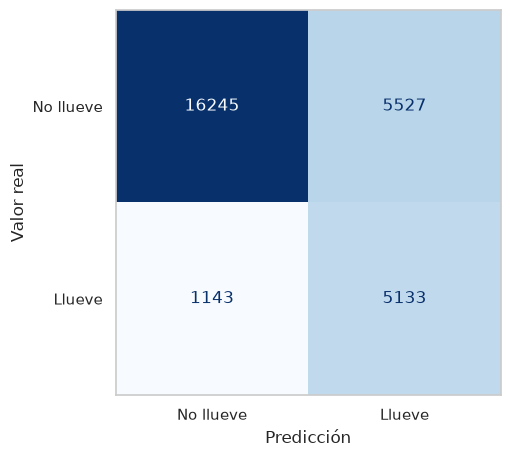

In [93]:
# Matriz de confusión del modelo elegido en prueba
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, prob_test >= umbral,
                                        display_labels=["No llueve", "Llueve"], cmap="Blues", values_format="d",
                                        colorbar=False, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
ax.grid(False)
plt.show()

*Figura 16. Matriz de confusión de la regresión logística sin balanceo con umbral 0,18, en prueba.*

En prueba el modelo detecta 5.133 de los 6.276 días de lluvia: el recall es 0,818, en línea con el 0,805
de validación, y los días de lluvia sin aviso son 1.143 (Figura 16). La precisión, en cambio, quedó en
0,482, por debajo del piso de 0,5 que fijamos: hubo 5.527 falsas alarmas, algo más de una por cada aviso
correcto. Era el riesgo anotado al elegir el umbral, que dejaba la precisión de validación en 0,501, sin
margen. No corregimos el umbral mirando este resultado.

La accuracy (0,762) queda por debajo del 0,776 de predecir siempre "No". No es una contradicción: es el
precio de haber elegido detectar la lluvia. Predecir siempre "No" acierta más días en total sin avisar
nunca, y por eso la accuracy no fue el criterio.

El AUC baja de 0,877 a 0,867 y la log loss sube de 0,341 a 0,355: el modelo ordena los días un poco peor
que en validación. Prueba es el período más reciente, de noviembre de 2015 a junio de 2017, y es el
conjunto donde más faltan `Sunshine` (66,8%) y `Evaporation` (56,9%), dos de las variables que más
separan las clases, así que más de sus valores son imputados. Es la explicación más compatible con lo que
vimos al dividir, pero con estos datos no podemos separar ese efecto del de que esos años hayan sido
distintos. Las probabilidades siguen calibradas: en promedio el modelo asigna 0,228 y llueve el 22,4% de
los días.

# Modelo base

Un modelo base no aprende casi nada, y sirve para saber si el modelo que construimos aporta algo. Usamos
dos:

- Siempre "No": contesta que no llueve todos los días. Es la clase mayoritaria, que aprende de
  entrenamiento. Marca el piso de la accuracy (acierta todos los días secos sin mirar ningún dato) y es
  el ejemplo de un modelo con buena accuracy que no detecta una sola lluvia.
- Persistencia: mañana pasa lo mismo que hoy. Predice lluvia si hoy llovió más de 1 mm (`Rainfall` > 1),
  que es la regla con la que el archivo define `RainToday`. En series de tiempo, repetir el último valor
  observado es un competidor difícil de ganar, y acá aprovecha el dato más directo que hay: si hoy llovió,
  mañana llueve el 46,8% de las veces, contra el 15,1% si no. Cuando falta `Rainfall` del día, predice
  "No".

Ninguno de los dos da probabilidades, así que no tienen umbral que elegir: cada uno es un único punto en
el espacio de la curva ROC. Los comparamos con la regresión logística en prueba, sobre los mismos días.

In [94]:
# Predicciones de los dos modelos base y de la regresión logística en prueba
from sklearn.dummy import DummyClassifier

siempre_no = DummyClassifier(strategy="most_frequent").fit(X_train_prep, y_train)
predicciones_test = {"siempre No": siempre_no.predict(X_test_prep),
                     "persistencia": X_test["Rainfall"].gt(1).astype(int).to_numpy(),
                     "regresión logística": (prob_test >= umbral).astype(int)}
print(f"Días de prueba sin Rainfall, en los que la persistencia predice 'No': {X_test['Rainfall'].isna().sum()} de {len(X_test)}")

Días de prueba sin Rainfall, en los que la persistencia predice 'No': 245 de 28048


In [95]:
def metricas_prediccion(y, prediccion):
    """Accuracy, precisión, recall, F1 y cantidad de errores de la clase lluvia para predicciones ya tomadas."""
    vn, fp, fn, vp = confusion_matrix(y, prediccion).ravel()
    return {"accuracy": accuracy_score(y, prediccion), "precisión": precision_score(y, prediccion, zero_division=0),
            "recall": recall_score(y, prediccion), "F1": f1_score(y, prediccion),
            "falsos negativos": fn, "falsos positivos": fp}

In [96]:
# Los dos modelos base contra la regresión logística, en prueba
pd.DataFrame.from_dict({nombre: metricas_prediccion(y_test, prediccion) for nombre, prediccion in predicciones_test.items()},
                       orient="index").round(3)

,accuracy,precisión,recall,F1,falsos negativos,falsos positivos
siempre No,0.776,0.000,0.000,0.000,6276,0
persistencia,0.753,0.448,0.443,0.446,3494,3429
regresión logística,0.762,0.482,0.818,0.606,1143,5527


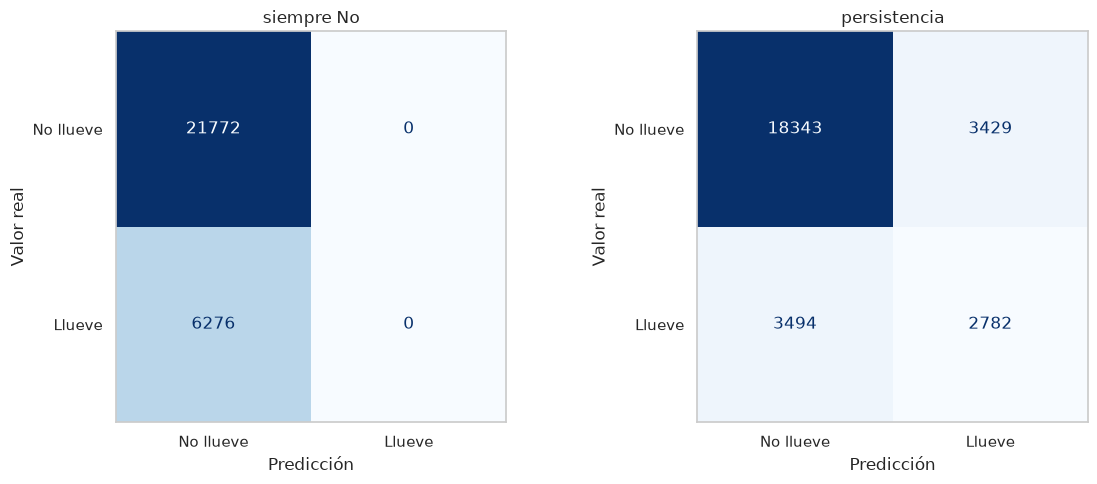

In [97]:
# Matrices de confusión de los dos modelos base en prueba
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes, ["siempre No", "persistencia"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones_test[nombre], display_labels=["No llueve", "Llueve"],
                                            cmap="Blues", values_format="d", colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
plt.tight_layout()
plt.show()

*Figura 17. Matrices de confusión de los modelos base siempre "No" (izquierda) y persistencia (derecha), en prueba.*

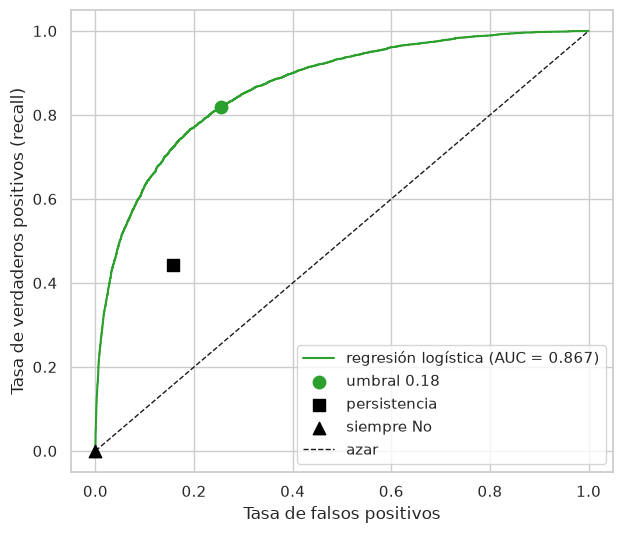

In [98]:
# Curva ROC de la regresión logística en prueba, con los modelos base y el umbral elegido como puntos
fig, ax = plt.subplots(figsize=(7, 6))
fpr, tpr, _ = roc_curve(y_test, prob_test)
ax.plot(fpr, tpr, color=COLORES_MODELO["sin balanceo"], label=f"regresión logística (AUC = {roc_auc_score(y_test, prob_test):.3f})")
for nombre, marcador in [("regresión logística", "o"), ("persistencia", "s"), ("siempre No", "^")]:
    vn, fp, fn, vp = confusion_matrix(y_test, predicciones_test[nombre]).ravel()
    etiqueta = f"umbral {umbral}" if nombre == "regresión logística" else nombre
    ax.scatter(fp / (fp + vn), vp / (vp + fn), marker=marcador, s=80, color="black" if nombre != "regresión logística" else COLORES_MODELO["sin balanceo"],
               zorder=3, label=etiqueta)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.legend(loc="lower right")
plt.show()

*Figura 18. Curva ROC de la regresión logística en prueba, con el punto de su umbral elegido y los puntos de los dos modelos base.*

In [99]:
# Recall de la regresión logística con la misma tasa de falsas alarmas que la persistencia
vn, fp, fn, vp = confusion_matrix(y_test, predicciones_test["persistencia"]).ravel()
tasa_fp_persistencia = fp / (fp + vn)
print(f"Persistencia: tasa de falsas alarmas {tasa_fp_persistencia:.3f}, recall {vp / (vp + fn):.3f}  |  "
      f"Regresión logística con la misma tasa: recall {np.interp(tasa_fp_persistencia, fpr, tpr):.3f}")

Persistencia: tasa de falsas alarmas 0.157, recall 0.443  |  Regresión logística con la misma tasa: recall 0.723


La regresión logística les gana a los dos modelos base en lo que decidimos medir. Siempre "No" tiene la
mejor accuracy de los tres (0,776) y no detecta ninguno de los 6.276 días de lluvia (Figura 17): es el
caso extremo de por qué la accuracy no podía ser el criterio. La persistencia detecta 2.782 (recall
0,443) y deja sin aviso 3.494. La regresión logística detecta 5.133 (recall 0,818) y deja sin aviso
1.143, un tercio que la persistencia.

La logística da más falsas alarmas que la persistencia (5.527 contra 3.429), pero porque con el umbral
0,18 avisa mucho más seguido. Comparadas en igualdad de condiciones, con la misma tasa de falsas alarmas
que tiene la persistencia (0,157), la logística detecta el 72,3% de las lluvias contra el 44,3%: en la
Figura 18, el punto de la persistencia queda muy por debajo de la curva. Y aun con su umbral bajo, la
precisión de la logística es mayor (0,482 contra 0,448).

La persistencia no es un competidor trivial. Con una sola variable acierta casi la mitad de sus avisos,
lo que confirma que la lluvia del día es de lo más informativo que hay. La regresión logística le suma el
resto de las mediciones del día, y eso es lo que le permite casi duplicar las lluvias detectadas con la
misma cantidad de falsas alarmas.